# End-to-End Machine Learning: Heart Disease Case Study

**Platform:** macOS, Apple Silicon (`arm64`)  
**Editor:** Visual Studio Code (VS Code), with Microsoft Python and Jupyter extensions  
**Environment manager:** Miniforge / Conda  
**Project environment:** `ml_end2end` (Python 3.12.16)  
**Project folder:** `ml_end2end`  
**Notebook:** `ml_end2end.ipynb`  
**Input dataset:** `input/data/heart_disease_df_1.csv`

**Source and adaptation.** This independent educational notebook is based on DataCamp’s *End-to-End Machine Learning* course. Its exercises and implementations have been adapted, expanded, refined, and supplemented with explanatory material on reproducibility, validation, and machine learning operations. DataCamp is the foundational instructional source; of course, this notebook is not endorsed by DataCamp.

This notebook serves two purposes:

1) Document the actual setup (completed on a Mac), including commands, diagnostics, and troubleshooting.
2) Teach exploratory analysis and preprocessing with pandas, Matplotlib, and scikit-learn. 

Most setup sections are documentation, not commands that must be rerun every time.

### Learning objectives

1. Distinguish the macOS shell, VS Code, Conda environment, Python interpreter, and Jupyter kernel.
2. Select the correct notebook kernel and verify the working directory and CSV path.
3. Explore and clean the heart-disease dataset.
4. Split training and testing data and avoid preprocessing leakage.
5. Compare min–max normalization and z-score standardization.
6. Fit classifiers, select features, evaluate predictions, and distinguish cross-validation from held-out testing.
7. Explore experiment tracking, automated inference tests, feature stores, monitoring, and feedback loops.

> **Status:** The user must confirm the dedicated environment, package imports, notebook interpreter, working directory, and CSV access in VS Code.

## 0. VS Code and Conda Setup on macOS — Verified Project Walkthrough

### 0.1 What each component does

| Component | Purpose | In this project |
|---|---|---|
| **macOS Terminal / VS Code integrated terminal** | Runs shell commands, such as `pwd` and `conda activate`. | The terminal shell shown during setup was Bash. macOS's suggestion to switch to zsh is informational; switching is not required. |
| **VS Code** | Opens and edits the project and notebook. | Open the entire `ml_end2end` folder, not just the notebook file. |
| **Microsoft Python extension** | Finds Python interpreters and Conda environments. | Installed/enabled through VS Code's suggested extensions. |
| **Microsoft Jupyter extension** | Runs `.ipynb` notebooks in the editor. | Installed/enabled through the same suggestion. |
| **Miniforge / Conda** | Manages isolated Python installations and libraries. | Miniforge resides in `~/miniforge3`. |
| **Conda environment** | Collection of a Python interpreter and installed packages. | `ml_end2end` with Python 3.12.16. |
| **Jupyter kernel** | The Python process executing notebook cells. | Selected interpreter: `~/miniforge3/envs/ml_end2end/bin/python`. |
| **Working directory (WD)** | Base directory for relative file paths. | `ml_end2end`. |

**VS Code interface (Mac):** 

- Explorer (left sidebar) shows files.
- Extensions (four-square icon) installs editor support.
- **Terminal → New Terminal** opens a shell.
- **Select Kernel** (notebook upper-right) chooses the interpreter for code cells.
- **⇧⌘P** opens the Command Palette.

### 0.2 Verified project layout and cleanup

Originally an RStudio project, it migrated to VS Code. The following obsolete project files were removed during setup, not by this notebook: `ml_end2end.Rproj`, `.Rproj.user/`, and `.Rhistory`. 

No `.RData` file existed. The macOS Finder metadata file `.DS_Store` is harmless and may remain.

```text
ml_end2end/
├── .DS_Store                         # Optional macOS Finder metadata
├── ml_end2end.ipynb                  # This notebook
└── input/
    └── data/
        └── heart_disease_df_1.csv   # Existing local dataset
```

Do not rerun deletion commands as part of the analysis. Neither this notebook nor its setup diagnostics modifies or deletes project files. Keep the CSV file and notebook where they are.

### 0.3 Open and trust the project folder

1. In VS Code, select **File → Open Folder…** and open `ml_end2end`.
2. If prompted, trust this folder only if you recognize its contents. Restricted Mode can prevent notebook and extension functionality.
3. In **Extensions**, install or enable **Python (Microsoft)** and **Jupyter (Microsoft)**; in the original setup, **Select Kernel → Install/Enable suggested extensions — Python + Jupyter** is the needed action.
4. Open `ml_end2end.ipynb` in the Explorer; the notebook contains Markdown cells (explanations) and code cells (executed by Python).
5. Open **Terminal → New Terminal** and confirm the project directory using `pwd`.

### 0.4 Verify macOS architecture and Miniforge (terminal commands)

The following commands belong in the terminal, not in a Python notebook cell. They were used during the original setup:

```bash
# Confirm Apple Silicon
uname -m

# Confirm the current project directory
pwd

# Check the available Python and Conda tools
python --version
which python
conda --version
conda env list
```

### 0.5 Create and activate the dedicated environment

The following commands document how the environment was created. **Do not recreate it if it already exists.** 

The `-c conda-forge` option chooses the conda-forge package channel; Python 3.12 was selected for broad scientific-package compatibility on Apple Silicon.

```bash
# One-time creation (already done on this Mac)
conda create -n ml_end2end -c conda-forge python=3.12

# Activate the existing environment in a new terminal session
conda activate ml_end2end

# Verify that the prompt starts with (ml_end2end) and Python is correct
python --version
which python
```

Expected active interpreter: `~/miniforge3/envs/ml_end2end/bin/python` (Python 3.12.16). 

The prompt's `(ml_end2end)` identifies the **environment**; the `:ml_end2end` after the computer name identifies the **working directory**. Environment and working directory are different concepts.

### 0.6 Install dependencies

With `(ml_end2end)` visible in the terminal, the packages were installed with:

```bash
conda install -c conda-forge pandas numpy matplotlib seaborn scikit-learn ipykernel
```

| Package | Role |
|---|---|
| `pandas` | DataFrames, CSV loading, inspection and cleaning |
| `numpy` | Numerical operations and array reshaping |
| `matplotlib` | Histograms and plots |
| `seaborn` | Optional statistical plotting library, installed and verified |
| `scikit-learn` | Splitting, imputation, normalization, standardization |
| `ipykernel` | Runs Python code in a VS Code notebook |

A standalone JupyterLab installation is not required to execute notebooks through VS Code's Jupyter extension when `ipykernel` is installed. 

### 0.7 Confirm imports in the *active* environment

```bash
# Run in the VS Code terminal after conda activate ml_end2end
python -c "import pandas, numpy, matplotlib, seaborn, sklearn, ipykernel; print('All required packages imported successfully.')"
```

New terminals may start in `(base)`. So this command succeeded in `(ml_end2end)` but failed with `ModuleNotFoundError: No module named 'seaborn'` when run from `(base)`. The fix is to activate `ml_end2end`, not to reinstall everything into `base`. That is, the fix is to activate the project environment when using terminal commands. 

The notebook kernel can remain correct even if the terminal later shows `(base)`.

### 0.8 Select the correct notebook kernel in VS Code

1. Click **Select Kernel** in the upper-right of `ml_end2end.ipynb`.
2. Choose **Python Environments**.
3. Choose **`ml_end2end (Python)`** with interpreter `~/miniforge3/envs/ml_end2end/bin/python`.
4. Do not select VS Code's suggested `/usr/bin/python3` system Python, Conda `base`, or **Create Python Environment** (the project environment already exists).
5. Run the next diagnostic cell (below) to verify the actual notebook kernel. 

Keep in mind that VS Code's terminal environment and notebook kernel are independently selected.

### 0.9 Working directory and relative paths

The working directory determines how Python interprets `input/data/heart_disease_df_1.csv`. The confirmed WD was `ml_end2end`. 

The working directory and the notebook file location are not automatically identical in every VS Code configuration. Check the diagnostic output rather than assuming. The code below reports the interpreter, version, WD, Conda environment, directory contents, and CSV accessibility without changing any files.

### 0.10 How to work through this notebook

- Run the diagnostic cell (below) first, then proceed from top to bottom.
- A code cell's ▶ button runs that cell; Markdown cells provide explanation only.
- Variables created in one code cell remain available to later cells until the kernel is restarted.
- Saving the notebook preserves its cells and optionally their outputs, not the kernel's live variables.
- After you understand each step, **Restart Kernel → Run All** is a useful reproducibility check.
- If imports fail, inspect `sys.executable` in the notebook and `which python` in the terminal: they may refer to different environments.


In [8]:

# =============================================================================
# 0A. DIAGNOSE THE PYTHON KERNEL AND PROJECT ENVIRONMENT
# =============================================================================

# Run this cell first to verify the Python environment and project structure
# This cell performs read-only diagnostics and stops execution if validation fails
# It does not create, modify, or delete project files

# Import cross-platform filesystem utilities
from pathlib import Path

# Import Python runtime information
import sys

# Import environment variable utilities
import os

# Identify the current working directory without displaying its absolute path
working_directory = Path.cwd()

# Retrieve the active environment name, when available
# conda_environment = os.environ.get("CONDA_DEFAULT_ENV", "Not set")

# Display portable Python environment information
print("Python version:", sys.version.split()[0])
print("Python implementation:", sys.implementation.name)
# print("Conda environment:", conda_environment)
print("Working directory:", working_directory.name)

# List immediate project files and directories without exposing parent paths
print("\nItems in the current working directory:")

for item in sorted(
    working_directory.iterdir(),
    key=lambda path: path.name.lower()
):
    item_type = "[DIR]" if item.is_dir() else "[FILE]"
    print(f"  {item_type} {item.name}")

# Define the expected CSV location relative to the project directory
relative_csv_path = Path("input") / "data" / "heart_disease_df_1.csv"

# Check whether the CSV exists without displaying its absolute location
print("\nExpected CSV:", relative_csv_path.as_posix())
print("CSV exists:", relative_csv_path.is_file())

# Stop execution if the required source data is unavailable
if not relative_csv_path.is_file():
    raise FileNotFoundError(
        "Required CSV not found at the expected project-relative location"
    )

# Resolve the expected environment directory relative to the project root
expected_environment = (working_directory / ".conda").resolve()

# Resolve the environment associated with the active Python interpreter
active_environment = Path(sys.prefix).resolve()

# Check whether the active interpreter belongs to the project-local environment
is_project_local = active_environment == expected_environment

# Display the verification result without exposing absolute paths
print("\nProject-local interpreter:", is_project_local)

# Stop execution if the notebook is using an unexpected Python environment
if not is_project_local:
    raise RuntimeError(
        "Incorrect Python environment: this notebook requires the "
        "project-local .conda environment. Select the corresponding "
        "Jupyter kernel in VS Code before continuing."
    )


Python version: 3.12.16
Python implementation: cpython
Working directory: ml_end2end

Items in the current working directory:
  [DIR] .conda
  [DIR] .git
  [FILE] .gitignore
  [FILE] .nojekyll
  [FILE] build_site.py
  [FILE] index.html
  [DIR] input
  [FILE] ml_end2end.ipynb
  [FILE] notebook-base.css
  [FILE] publication.css
  [FILE] README.md
  [FILE] site.js

Expected CSV: input/data/heart_disease_df_1.csv
CSV exists: True

Project-local interpreter: True


### 0.11 Interpreting the Verified Notebook Diagnostics

The diagnostic cell immediately above was successfully executed in VS Code during setup on Windows and reported:

| Diagnostic | Verified output |
|---|---|
| **Python version** | `3.12.16` |
| **Python implementation** | `cpython` |
| **Working directory** | `ml_end2end` |
| **Expected dataset path** | `input/data/heart_disease_df_1.csv` |
| **CSV exists** | `True` |
| **Project-local interpreter** | `True` |

These results confirm that the notebook is executing with Python 3.12.16 from the project's local `.conda` environment, that its working directory is the project root, and that the required input dataset is accessible through a relative path.

The diagnostic cell includes two mandatory validation checkpoints:

1. **Dataset availability:** Raises `FileNotFoundError` if the required CSV cannot be found at its expected project-relative location.
2. **Interpreter validation:** Raises `RuntimeError` if the active Python environment does not match the project's `.conda` directory.

Both checks must pass before sequential notebook execution can proceed. These checks validate the execution environment and input-file availability, but do not establish that all dependencies are installed or that the complete analytical workflow has been successfully executed.

The project-local `.conda` directory contains the Python interpreter and installed packages for the current operating system. It is excluded from Git version control and must be recreated independently on each computer. The same project-relative directory structure can be used on macOS, Windows, and Linux without hardcoding machine-specific paths.

> **If validation fails:** Open the project root folder in VS Code, select the Python interpreter from the project's `.conda` directory, and rerun the diagnostic cell. If the interpreter is correct but the working directory is not, inspect the VS Code workspace settings and notebook launch configuration. Avoid hardcoding machine-specific absolute paths. The subsequent CSV-loading code should use project-relative paths and provide a clear error when the required dataset cannot be located.

The code below continues with the machine learning analysis. The complete analytical workflow has not yet been verified by executing every cell in the newly configured environment.

### Optional: Reproduce the Environment Later

The setup above is already complete. For a future Mac or a fresh installation, open the project folder, create/activate the Conda environment, install the listed dependencies, select its kernel, and run the diagnostics. 

The user can optionally export a reproducible environment specification from the terminal using `conda env export --from-history -n ml_end2end > environment.yml` (review the file before committing it). This command is not executed by this notebook. 

`.gitignore` and `environment.yml` are optional project-maintenance additions, not prerequisites for this analysis.

> **Security and data handling:** Trust only known VS Code workspaces; do not execute unfamiliar notebooks or terminal commands without reviewing them. The notebook reads the local CSV and does not fetch data from external services.

In [13]:
# =============================================================================
# 0. IMPORT LIBRARIES AND CONFIGURE DISPLAY
# =============================================================================

# pathlib.Path
# Construct filesystem paths in a portable way (macOS, Linux, and Windows) without hard-coding machine-specific absolute paths
from pathlib import Path

# NumPy
# Use numerical arrays and basic numerical checks
import numpy as np

# pandas
# Load, inspect, clean, and manipulate tabular data
import pandas as pd

# Matplotlib
# Bild and customize exploratory visualizations
import matplotlib.pyplot as plt

# scikit-learn
# Split observations and fit reusable preprocessing objects
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer

# Increase the number of columns shown when displaying a DataFrame
pd.set_option("display.max_columns", 50)

print("pandas version:", pd.__version__)
print("Current working directory:", Path.cwd().name)

pandas version: 3.1.0
Current working directory: ml_end2end


## 1. Load the Exact CSV in This Project

The notebook develops a reproducible workflow while retaining focused demonstrations of individual methods.

First, it loads the supplied CSV into the pandas DataFrame `heart_disease_df` using `pd.read_csv()`.

The path-resolution helper searches for `input/data/heart_disease_df_1.csv` in the current working directory and its parent directories. 

If the file is unavailable, execution stops rather than silently loading a different dataset (or creating an empty DataFrame).


In [22]:
# =============================================================================
# 1. LOAD THE LOCAL HEART DISEASE DATASET
# =============================================================================

# Relative location of the CSV within the VS Code workspace
# Keep this path unchanged (unless you move or rename the source file)
relative_csv_path = Path("input") / "data" / "heart_disease_df_1.csv"

# Search the current working directory and each of its parents
# This handles launches from the project root and some subdirectories
search_roots = (Path.cwd(), *Path.cwd().parents)

matching_paths = [
    root / relative_csv_path
    for root in search_roots
    if (root / relative_csv_path).is_file()
]

# Raise a clear error if the expected file is not present
# Rather than loading the wrong dataset or creating an empty DataFrame 
if not matching_paths and (Path.cwd() / "heart_disease_df_1.csv").is_file():
    # Allow the supplied CSV to sit beside the notebook in a portable copy
    matching_paths = [Path.cwd() / "heart_disease_df_1.csv"]

if not matching_paths:
    raise FileNotFoundError(
        "Cannot locate input/data/heart_disease_df_1.csv. "
        "Open the ml_end2end folder in VS Code and check the notebook working directory. "
        f"Current working directory: {Path.cwd()}"
    )

# Use the nearest matching project-relative file
csv_path = matching_paths[0]

# Read the CSV into memory as a pandas DataFrame
# IMPORTANT: pandas infers column types from the data unless instructed otherwise
heart_disease_df = pd.read_csv(csv_path)

# Display the dataset path relative to the project root
print("Loaded dataset:\n", csv_path.relative_to(Path.cwd()).as_posix())

# Inspect DataFrame dimensions
print("\nRows and columns:\n", heart_disease_df.shape)
print("\nColumn names:\n", heart_disease_df.columns.tolist())

Loaded dataset:
 input/data/heart_disease_df_1.csv

Rows and columns:
 (1076, 14)

Column names:
 ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


# Case Study: Predicting Heart Disease

A typical machine learning lifecycle includes:

1. Understanding and defining the problem
2. Collecting and preparing data
3. Engineering or selecting features
4. Training and evaluating models
5. Deploying a model
6. Monitoring its behavior over time

**Exploratory data analysis (EDA)** helps us understand the dataset before modeling. We inspect missing values, class balance, distributions, unusual observations, and potential data-quality problems. 

These findings inform preprocessing choices and suggest questions worth investigating.

Here, the notebook develops a typical classification routine.


## 2. Inspect the DataFrame

- `.head()` returns the first five rows by default.
- `.info()` prints a structural summary and returns `None`, so do not wrap it in `print()`.
- `.shape` is an attribute, not a method; it returns `(rows, columns)`.
- `.isna().sum()` counts missing entries by column.

These checks are especially useful before choosing cleaning or modeling strategies.

In [23]:
# =============================================================================
# 2. INITIAL DATAFRAME INSPECTION
# =============================================================================

# Preview the first five observations and all available columns
print("First five rows:")
print(heart_disease_df.head())

First five rows:
   age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0   52    1  0.0       125  212.0    0      1.0      168      0      NaN   
1   53    1  0.0       140  203.0    1      0.0      155      1      NaN   
2   70    1  0.0       145  174.0    0      1.0      125      1      NaN   
3   61    1  0.0       148  203.0    0      1.0      161      0      NaN   
4   62    0  0.0       138  294.0    1      1.0      106      0      NaN   

   slope  ca  thal  target  
0      2   2     3       0  
1      0   0     3       0  
2      0   0     3       0  
3      2   1     3       0  
4      1   3     2       0  


In [26]:
# Print number of non-null observations, inferred dtypes, and memory use
# IMPORTANT: .info() itself prints without returning a value, so we do not wrap it in print()
print("DataFrame structure:")
heart_disease_df.info()

DataFrame structure:
<class 'pandas.DataFrame'>
RangeIndex: 1076 entries, 0 to 1075
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1076 non-null   int64  
 1   sex       1076 non-null   int64  
 2   cp        1023 non-null   float64
 3   trestbps  1076 non-null   int64  
 4   chol      1021 non-null   float64
 5   fbs       1076 non-null   int64  
 6   restecg   1028 non-null   float64
 7   thalach   1076 non-null   int64  
 8   exang     1076 non-null   int64  
 9   oldpeak   0 non-null      float64
 10  slope     1076 non-null   int64  
 11  ca        1076 non-null   int64  
 12  thal      1076 non-null   int64  
 13  target    1076 non-null   int64  
dtypes: float64(4), int64(10)
memory usage: 117.8 KB


In [ ]:
# print(.info()) would also return None
# This behavior is expected because .info() is designed to print directly to the console
print(heart_disease_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1076 entries, 0 to 1075
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1076 non-null   int64  
 1   sex       1076 non-null   int64  
 2   cp        1023 non-null   float64
 3   trestbps  1076 non-null   int64  
 4   chol      1021 non-null   float64
 5   fbs       1076 non-null   int64  
 6   restecg   1028 non-null   float64
 7   thalach   1076 non-null   int64  
 8   exang     1076 non-null   int64  
 9   oldpeak   0 non-null      float64
 10  slope     1076 non-null   int64  
 11  ca        1076 non-null   int64  
 12  thal      1076 non-null   int64  
 13  target    1076 non-null   int64  
dtypes: float64(4), int64(10)
memory usage: 117.8 KB
None


In [35]:
# .shape is an attribute, not a method
# Attributes do not require parentheses when accessed
# .shape returns a tuple: (number_of_rows, number_of_columns)
print("Dimensions (rows, columns):\n", heart_disease_df.shape)

# Count missing values independently for each column
print("\nMissing values by column:")
print(heart_disease_df.isna().sum())

Dimensions (rows, columns):
 (1076, 14)

Missing values by column:
age            0
sex            0
cp            53
trestbps       0
chol          55
fbs            0
restecg       48
thalach        0
exang          0
oldpeak     1076
slope          0
ca             0
thal           0
target         0
dtype: int64


In [34]:
# Check whether all values in the oldpeak column are missing
print("All values are missing:")
print(heart_disease_df["oldpeak"].isna().all())

All values are missing:
True


## 3. Explore Categorical Values: `sex`

For a categorical column, `.value_counts()` reports the number of observations in each category. This reveals how frequently each encoded value appears in the data.

By contrast, `.count()` returns the total number of non-missing entries, without separating categories. 

Neither method alone establishes whether the target classes are balanced.


In [33]:
# =============================================================================
# 3. COUNT VALUES IN THE SEX COLUMN
# =============================================================================

# .value_counts() returns counts per unique observed value
# Values are ordered from most frequent to least frequent; missing values are excluded by default
print("Counts by sex code:")
print(heart_disease_df["sex"].value_counts())

Counts by sex code:
sex
1    743
0    333
Name: count, dtype: int64


In [36]:
# .count() returns a count of all non-missing entries
print("Count of non-missing entries:")
print("sex:\n", heart_disease_df["sex"].count())
print("cp:\n", heart_disease_df["cp"].count())

Count of non-missing entries:
sex:
 1076
cp:
 1023


In [37]:
# Include missing values to check whether category counts cover all rows
print("Counts including missing values:")
print(heart_disease_df["sex"].value_counts(dropna=False))

Counts including missing values:
sex
1    743
0    333
Name: count, dtype: int64


In [38]:
# Examine the distribution of cp values, a feature known to contain missing observations
print(heart_disease_df["cp"].value_counts(dropna=False))

cp
0.0    491
2.0    289
1.0    169
3.0     74
NaN     53
Name: count, dtype: int64


In [ ]:
# Compare .value_counts() with and without dropna=False
print("Without dropna=False:")
print(heart_disease_df["cp"].value_counts())

print("\nWith dropna=False:")
print(heart_disease_df["cp"].value_counts(dropna=False))

Without dropna=False:
cp
0.0    491
2.0    289
1.0    169
3.0     74
Name: count, dtype: int64

With dropna=False:
cp
0.0    491
2.0    289
1.0    169
3.0     74
NaN     53
Name: count, dtype: int64


In [42]:
# normalize=True reports shares of the non-missing observations, not counts
print("Proportions among non-missing observations:")
print(heart_disease_df["sex"].value_counts(normalize=True))

Proportions among non-missing observations:
sex
1    0.69052
0    0.30948
Name: proportion, dtype: float64


In [43]:
# Express the distribution of sex categories as percentages, excluding missing observations
print("Percentages among non-missing observations:")
print(heart_disease_df["sex"].value_counts(normalize=True) * 100)

Percentages among non-missing observations:
sex
1    69.052045
0    30.947955
Name: proportion, dtype: float64


### *EXPLORE FURTHER*
**Compare several categorical predictors**

The earlier `sex` frequency exercise demonstrates `value_counts()` for one variable. Here, the same operation is applied to a few other categorical predictors. Numeric category codes are treated as labels, not as continuous measurements. Including missing values makes incomplete categories visible without imputing them prematurely.

In [44]:
# =============================================================================
# 3.1. COMPARE FREQUENCIES ACROSS CATEGORICAL PREDICTORS
# =============================================================================

# These columns represent categories, even though their values are numeric
categorical_features_eda = ["sex", "cp", "restecg", "exang", "thal"]

# Create one concise frequency table per predictor
for feature in categorical_features_eda:
    category_counts = heart_disease_df[feature].value_counts(
        dropna=False
    ).sort_index()
    print(f"\n{feature} — category counts (including missing values):")
    print(category_counts)


sex — category counts (including missing values):
sex
0    333
1    743
Name: count, dtype: int64

cp — category counts (including missing values):
cp
0.0    491
1.0    169
2.0    289
3.0     74
NaN     53
Name: count, dtype: int64

restecg — category counts (including missing values):
restecg
0.0    501
1.0    512
2.0     15
NaN     48
Name: count, dtype: int64

exang — category counts (including missing values):
exang
0    719
1    357
Name: count, dtype: int64

thal — category counts (including missing values):
thal
0      7
1     65
2    571
3    433
Name: count, dtype: int64


## 4. Visualize Cholesterol (`chol`)

A histogram groups numerical measurements into intervals, called bins, and shows how many observations fall into each interval.

pandas `.plot(kind="hist")` creates the plot, and Matplotlib adds labels and displays the figure. 

This first example focuses on cholesterol before a later extension examines several numerical predictors.


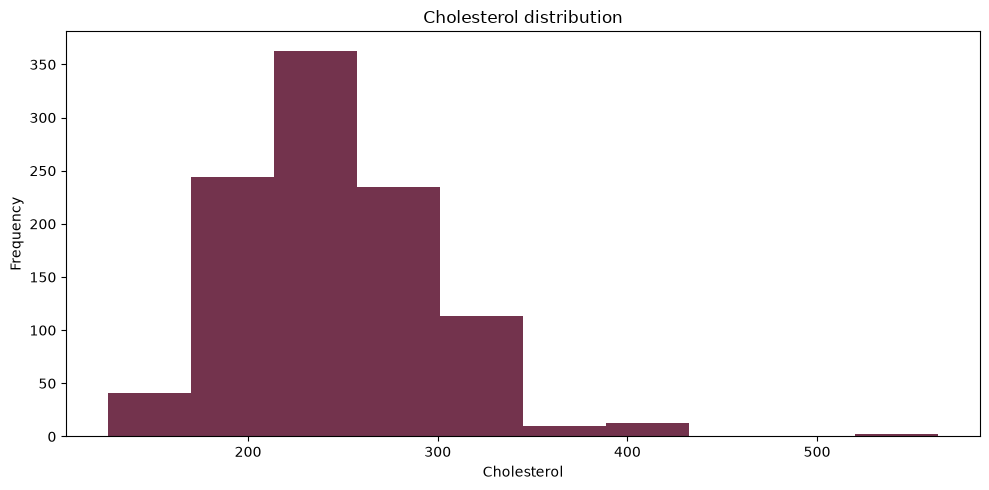

In [47]:
# =============================================================================
# 4. HISTOGRAM OF CHOLESTEROL
# =============================================================================

# Select a column of interest
# Missing values are omitted by pandas' histogram implementation
if "chol" not in heart_disease_df.columns:
    raise KeyError("Expected a 'chol' column in the source CSV.")

# Start a new figure so subsequent plots do not overlap this histogram
plt.figure(figsize=(10, 5))

# Plot
# The default number of bins is 10 unless specified explicitly
heart_disease_df["chol"].plot(
    kind="hist", 
    color="#73334d"
)

# Add a title and descriptive axis labels
plt.title("Cholesterol distribution")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")

# Adjust spacing and render the plot
plt.tight_layout()
plt.show()

### *EXPLORE FURTHER*
**Examine the distributions of several numerical predictors**

The cholesterol histogram introduces one-variable exploration. A small collection of histograms makes it easier to notice different ranges, skew, and unusual values across other measured predictors. This is all about descriptive exploration. Missing observations are omitted from the plots; the missing-value investigation and subsequent preprocessing remain separate exercises.

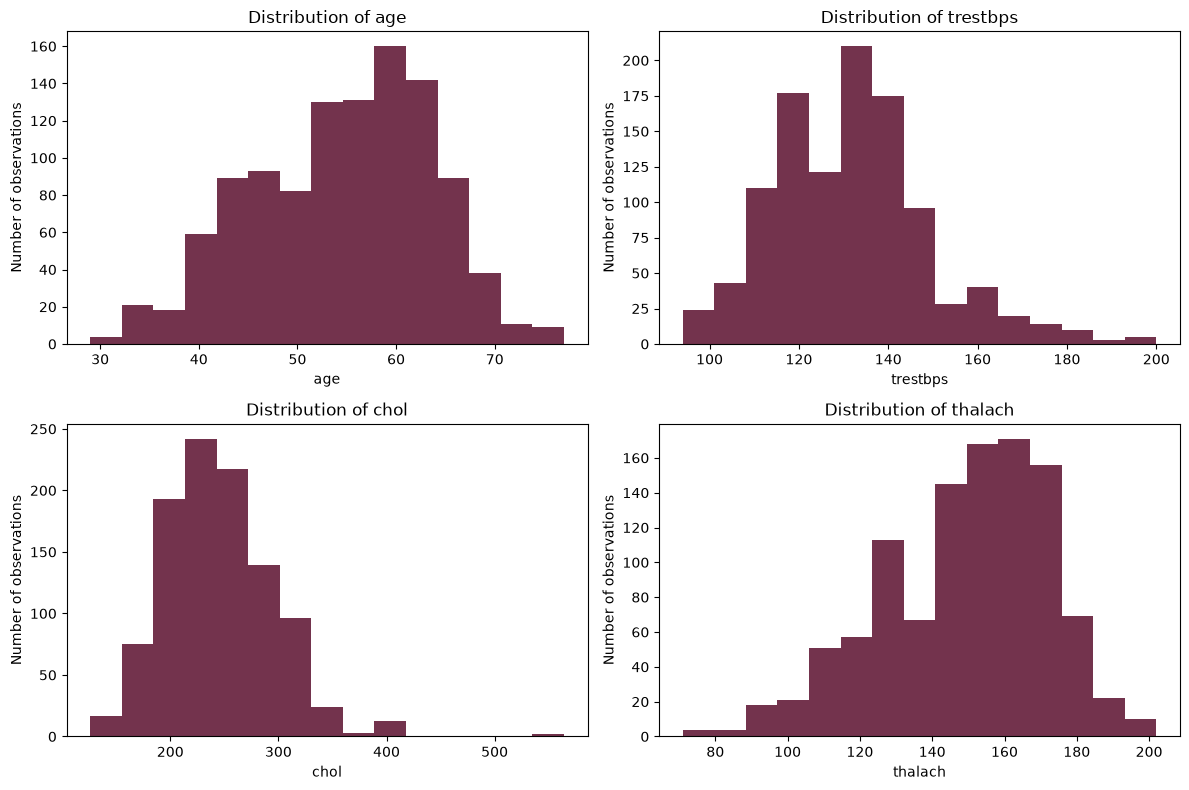

In [48]:
# =============================================================================
# 4.1. COMPARE DISTRIBUTIONS OF CONTINUOUS PREDICTORS
# =============================================================================

# Select measurements rather than numerically encoded categories
# Keep the original cholesterol histogram above as the single-variable example
continuous_features = ["age", "trestbps", "chol", "thalach"]

# A 2-by-2 grid keeps the comparison readable without adding new libraries
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Each Series.hist() ignores missing values for visualization only
# The underlying DataFrame is not modified
for axis, feature in zip(axes.flat, continuous_features):
    heart_disease_df[feature].hist(
        bins=15, 
        ax=axis, 
        color="#73334d", 
        grid=False
    )
    axis.grid(False)  # Keep the panels consistent with the individual histograms
    axis.set_title(f"Distribution of {feature}")
    axis.set_xlabel(feature)
    axis.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

# Data Preparation

We first investigate missing values and exact duplicates; then we decide what to remove.

In later preprocessing, we learn imputation and scaling parameters from **training data only** to avoid data leakage.

Removing exact duplicate rows before the split reduces the chance that identical records appear in both training and test partitions. 

At this stage, we care about empty or sparse rows and columns (`Null` values typically break code) and duplicates.

## 5. Remove `oldpeak` and Exact Duplicate Rows

The earlier missing-value investigation showed why `oldpeak` is a candidate for removal. 

So we use `.drop(columns=["oldpeak"])` to remove the column **after** examining it.

Next, `.drop_duplicates()` retains the first occurrence of each unique row by default. 

We always inspect the resulting DataFrame and its remaining missing values before proceeding.

> **Caution:** Identical measurements do not necessarily identify the same patient. This exercise removes exact duplicate rows, but real clinical data require additional evidence (ideally, unique identifiers) before interpreting them as duplicate individuals.


In [49]:
# =============================================================================
# 5. REMOVE AN UNWANTED COLUMN AND DUPLICATE ROWS
# =============================================================================

# Check whether oldpeak contains only NaN values
# The preceding exploration establishes the oldpeak column
# Here we measure its missingness before deciding whether to remove it
oldpeak_missing = heart_disease_df["oldpeak"].isna().sum()

print("Missing oldpeak values:\n", oldpeak_missing)
print("\nTotal rows:\n", len(heart_disease_df))
print("\nEntire oldpeak column missing:\n", heart_disease_df["oldpeak"].isna().all())

Missing oldpeak values:
 1076

Total rows:
 1076

Entire oldpeak column missing:
 True


In [58]:
# Remove oldpeak, a column known to contain only missing values
# A new DataFrame is returned, leaving heart_disease_df unchanged
heart_disease_column_dropped = heart_disease_df.drop(["oldpeak"], axis="columns")

# Verify that oldpeak is no longer present in the resulting DataFrame
print(
    "\nheart_disease_column_dropped has oldpeak column:\n", 
    "oldpeak" in heart_disease_column_dropped.columns.to_list()
)
print(
    "\nheart_disease_df has oldpeak column:\n", 
    "oldpeak" in heart_disease_df.columns.to_list()
)


heart_disease_column_dropped has oldpeak column:
 False

heart_disease_df has oldpeak column:
 True


In [59]:
# axis=1 and axis="columns" are equivalent; columns=["oldpeak"] is more explicit
heart_disease_column_dropped = heart_disease_df.drop(columns=["oldpeak"])

# Report the change in column count
print("Original dimensions:\n", heart_disease_df.shape)
print("\nAfter column removal:\n", heart_disease_column_dropped.shape)

Original dimensions:
 (1076, 14)

After column removal:
 (1076, 13)


In [62]:
# Remove exact duplicate rows across all remaining columns
# By default keep="first", so the first matching row is retained
heart_disease_duplicates_dropped = (
    heart_disease_column_dropped.drop_duplicates()
    .reset_index(drop=True) # gives the cleaned table a consecutive row index
)

# Report the change in row count and dimensions
removed_rows = len(heart_disease_column_dropped) - len(heart_disease_duplicates_dropped)

print("Rows removed as duplicates:\n", removed_rows)
print(
    "\nOriginal dimensions (heart_disease_df):\n", 
    heart_disease_df.shape
)
print(
    "\nAfter column removal (heart_disease_column_dropped):\n", 
    heart_disease_column_dropped.shape
)
print(
    "\nAfter duplicate removal (heart_disease_duplicates_dropped):\n", 
    heart_disease_duplicates_dropped.shape
)

Rows removed as duplicates:
 638

Original dimensions (heart_disease_df):
 (1076, 14)

After column removal (heart_disease_column_dropped):
 (1076, 13)

After duplicate removal (heart_disease_duplicates_dropped):
 (438, 13)


In [63]:
# Inspect the DataFrame after removing both the oldpeak column and the exact duplicates
print("Cleaned preview:")
print(heart_disease_duplicates_dropped.head())

Cleaned preview:
   age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  slope  ca  \
0   52    1  0.0       125  212.0    0      1.0      168      0      2   2   
1   53    1  0.0       140  203.0    1      0.0      155      1      0   0   
2   70    1  0.0       145  174.0    0      1.0      125      1      0   0   
3   61    1  0.0       148  203.0    0      1.0      161      0      2   1   
4   62    0  0.0       138  294.0    1      1.0      106      0      1   3   

   thal  target  
0     3       0  
1     3       0  
2     3       0  
3     3       0  
4     2       0  


In [64]:
# Inspect remaining missing values before selecting an imputation strategy
# We will have to fill missing data with substitutes (imputation)
print(heart_disease_duplicates_dropped.isna().sum())

age          0
sex          0
cp          49
trestbps     0
chol        49
fbs          0
restecg     44
thalach      0
exang        0
slope        0
ca           0
thal         0
target       0
dtype: int64


## 6. Calculate the Mean of `restecg`

A summary statistic can help fill missing values through a process called **imputation**. 

The pandas `.mean()` method calculates the arithmetic average of non-missing numerical observations.

However, `restecg` represents **categories encoded as numbers**. Its mean may therefore not correspond to any valid category. 

We calculate the mean here to demonstrate the operation. We will use the most frequent category (rather than the mean) for the actual modeling workflow.

More complex imputation approaches exist, but this exercise focuses on understanding why the chosen method must match the variable type.


In [68]:
# =============================================================================
# 6. INSPECT RESTECG AND CALCULATE ITS MEAN
# =============================================================================

# pandas .mean() excludes NaN by default and returns a numerical average
mean_value = heart_disease_duplicates_dropped["restecg"].mean()

# Show the mean of restecg 
print("Mean of restecg (demonstration only):", mean_value)

# Show category frequencies
# These are often more informative for categorical variables than a numerical average
print("\nrestecg value counts (including missing values):\n")
print(heart_disease_duplicates_dropped["restecg"].value_counts(dropna=False))

Mean of restecg (demonstration only): 0.5431472081218274

restecg value counts (including missing values):

restecg
1.0    198
0.0    188
NaN     44
2.0      8
Name: count, dtype: int64


### 6A. Mean Imputation: A Demonstration

First, fill missing `restecg` entries with `mean_value` on a separate demonstration copy. This preserves the cleaned dataset for later exercises.

Direct column assignment is preferable to `df['column'].fillna(..., inplace=True)`, which can lead to chained-assignment problems.

> **Do not use the full-dataset mean to prepare a predictive model.** It can incorporate information from observations that will later belong to the test set. After splitting the data, fit an appropriate categorical imputer on the training partition only.


In [72]:
# =============================================================================
# 6A. MEAN IMPUTATION ON A DEMONSTRATION COPY ONLY
# =============================================================================

# Copy the DataFrame so the original cleaned data remains untouched
restecg_mean_demo = heart_disease_duplicates_dropped.copy()

# fillna(value) replaces NaN entries and returns a new Series
# Directly assign the result back to the DataFrame column
restecg_mean_demo["restecg"] = (
    restecg_mean_demo["restecg"].fillna(mean_value)
)

# .isna() creates Boolean flags; .any() checks whether any are True
# If mean_value is a valid non-missing number, the expected result is False
print("Any missing restecg values after demo imputation?\n", restecg_mean_demo["restecg"].isna().any())

Any missing restecg values after demo imputation?
 False


In [76]:
# Demonstrate that mean imputation can create non-integer category codes
# Which is why we do not like this approach for categorical variables
print("\nUnique restecg values (BEFORE imputation):")
print(sorted(heart_disease_duplicates_dropped["restecg"].dropna().unique()))

print("\nUnique restecg values (AFTER imputation):")
print(sorted(restecg_mean_demo["restecg"].dropna().unique()))


Unique restecg values (BEFORE imputation):
[np.float64(0.0), np.float64(1.0), np.float64(2.0)]

Unique restecg values (AFTER imputation):
[np.float64(0.0), np.float64(0.5431472081218274), np.float64(1.0), np.float64(2.0)]


## 7. Define Predictors and Target, Then Split the Data

This section separates **target definition** and **train–test splitting** from the transformations introduced later. 

Normalization and standardization are distinct scaling methods and will be demonstrated after the split.

Feature selection and feature engineering are distinct as well. A random forest model can help us to determine which features are more meaningful.

`X` contains predictor columns; `y` contains the outcome to predict. An 80/20 split with `random_state=42` is reproducible. 

For a classification target, `stratify=y` helps maintain similar class proportions in both partitions when every class has enough observations. 

We keep unmodified copies of the resulting partitions to compare different transformations fairly.

> **Data leakage:** In a real predictive pipeline, all data-dependent preprocessing parameters, including imputers and scalers, must be learned using training data only.

In [77]:
# =============================================================================
# 7. DEFINE X AND y, AND CREATE TRAINING / TESTING PARTITIONS
# =============================================================================

# Confirm the target column exists
print('target' in heart_disease_duplicates_dropped.columns)


True


In [78]:
# Set column name explicitly if your dataset uses another outcome column name
TARGET_COLUMN = next(
    (name for name in ("target", "num")
     if name in heart_disease_duplicates_dropped.columns),
    None,
)

# Stop if the outcome cannot be identified safely
if TARGET_COLUMN is None:
    raise KeyError(
        "Could not identify the target column."
        "Inspect the CSV columns and set TARGET_COLUMN manually (for example, 'target' or 'num')."
    )

print("Outcome column selected:\n", TARGET_COLUMN)

Outcome column selected:
 target


In [79]:
# Set all columns (except the target) as predictors
X = heart_disease_duplicates_dropped.drop(columns=[TARGET_COLUMN])

print(X)

     age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  slope  ca  \
0     52    1  0.0       125  212.0    0      1.0      168      0      2   2   
1     53    1  0.0       140  203.0    1      0.0      155      1      0   0   
2     70    1  0.0       145  174.0    0      1.0      125      1      0   0   
3     61    1  0.0       148  203.0    0      1.0      161      0      2   1   
4     62    0  0.0       138  294.0    1      1.0      106      0      1   3   
..   ...  ...  ...       ...    ...  ...      ...      ...    ...    ...  ..   
433   54    1  0.0       120  188.0    0      1.0      113      0      1   1   
434   58    1  2.0       140    NaN    1      0.0      165      0      2   0   
435   45    1  1.0       128    NaN    0      0.0      170      0      2   0   
436   58    1  0.0       114    NaN    0      2.0      140      0      0   3   
437   58    1  0.0       128  216.0    0      0.0      131      1      1   3   

     thal  
0       3  
1       3  
2  

In [80]:
# Set the target
y = heart_disease_duplicates_dropped[TARGET_COLUMN]

print(y)

0      0
1      0
2      0
3      0
4      0
      ..
433    0
434    1
435    1
436    0
437    0
Name: target, Length: 438, dtype: int64


In [81]:
# This dataset is expected to be a classification dataset
# Stratification is only possible when target values: 
# (1) are non-missing, and
# (2) each class has enough observations to appear in both partitions
# Therefore
# Check for missing target values before attempting stratification
if y.isna().any():
    raise ValueError("Target contains missing values; resolve them before splitting.")

# Count observations in each target class to assess class distribution
class_counts = y.value_counts(dropna=False)

# Display class frequencies to identify potential imbalance or rare classes
print(class_counts)

target
1    230
0    208
Name: count, dtype: int64


In [82]:
# Calculate the number of observations allocated to each partition
n_classes = len(class_counts)
n_train = int(np.floor(0.80 * len(y)))
n_test = int(np.ceil(0.20 * len(y)))

# Check each requirement for stratified splitting
stratification_checks = {
    "At least two distinct target classes": n_classes > 1,
    "At least two observations per class": class_counts.min() >= 2,
    "Enough test observations for every class": n_test >= n_classes,
    "Enough training observations for every class": n_train >= n_classes,
}

# Stratification is feasible only when all four requirements are satisfied
can_stratify = all(stratification_checks.values())

# Display the observed values used to evaluate the requirements
print("STRATIFIED TRAIN-TEST SPLIT (80/20)")
print(f"Total observations: {len(y)}")
print(f"Target classes: {n_classes}")
print(f"Smallest class: {class_counts.min()} observations")
print(f"Training observations: {n_train}")
print(f"Testing observations: {n_test}")

# Report the result of each individual requirement
print("\nStratification requirements:")

for criterion, satisfied in stratification_checks.items():
    status = "PASS" if satisfied else "FAIL"
    print(f"  [{status}] {criterion}")

# Display the overall conclusion
print(
    "\nConclusion: "
    + (
        "Stratified splitting is feasible"
        if can_stratify
        else "Stratified splitting is not feasible"
    )
)

STRATIFIED TRAIN-TEST SPLIT (80/20)
Total observations: 438
Target classes: 2
Smallest class: 208 observations
Training observations: 350
Testing observations: 88

Stratification requirements:
  [PASS] At least two distinct target classes
  [PASS] At least two observations per class
  [PASS] Enough test observations for every class
  [PASS] Enough training observations for every class

Conclusion: Stratified splitting is feasible


In [83]:
# While y is all set, notice that X still has missing values
missing_counts = X.isna().sum()

print(missing_counts[missing_counts > 0])

cp         49
chol       49
restecg    44
dtype: int64


In [84]:
# Use a stratified split when feasible; otherwise fall back to random
# For a different task, you may need a group-based or time-based split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y if can_stratify else None,
)

# Copy each partition to make later transformations independent
# These snapshots retain the age values BEFORE any scaling
X_train_original = X_train.copy()
X_test_original = X_test.copy()

print("Stratified split used:\n", can_stratify)
print("\nX_train shape:\n", X_train.shape)
print("\nX_test shape:\n", X_test.shape)
print("\ny_train shape:\n", y_train.shape)
print("\ny_test shape:\n", y_test.shape)

Stratified split used:
 True

X_train shape:
 (350, 12)

X_test shape:
 (88, 12)

y_train shape:
 (350,)

y_test shape:
 (88,)


In [86]:
# Examine the distribution of target classes BEFORE and AFTER splitting

# Calculate the proportion of observations belonging to each class in the original dataset
class_proportions = y.value_counts(normalize=True)

print("Original target proportions:\n")
print(class_proportions)

Original target proportions:

target
1    0.525114
0    0.474886
Name: proportion, dtype: float64


In [87]:
# Compare class proportions in the training and test sets
# This assesses whether the split preserves the original target distribution
print("\nTraining target proportions:\n")
print(y_train.value_counts(normalize=True))

print("\nTesting target proportions:\n")
print(y_test.value_counts(normalize=True))


Training target proportions:

target
1    0.525714
0    0.474286
Name: proportion, dtype: float64

Testing target proportions:

target
1    0.522727
0    0.477273
Name: proportion, dtype: float64


### *EXPLORE FURTHER*
**Compare numerical measurements across target classes**

The target-frequency exercise establishes how common each outcome is. A simple grouped summary now asks whether observed measurements differ between classes. The original train-test split remains unchanged, and this table is not used to choose predictors or fit a model.

In [88]:
# =============================================================================
# 7.1. DESCRIBE NUMERICAL FEATURES BY TARGET CLASS
# =============================================================================

# Work with the cleaned DataFrame, retaining its existing target labels
# groupby() forms one group for each observed target category
comparison_features = ["age", "trestbps", "chol", "thalach"]

# mean() excludes missing values separately within each target group
# round(1) makes the descriptive summary easier to scan
class_feature_means = (
    heart_disease_duplicates_dropped
    .groupby(TARGET_COLUMN)[comparison_features]
    .mean()
    .round(1)
)

print("Mean measurements by observed target class:")
print(class_feature_means)

# Counts clarify how many cleaned observations contribute to each class
print("\nObservations by target class:")
print(heart_disease_duplicates_dropped[TARGET_COLUMN].value_counts().sort_index())

Mean measurements by observed target class:
         age  trestbps   chol  thalach
target                                
0       56.4     134.2  251.8    137.8
1       52.8     129.7  242.6    158.0

Observations by target class:
target
0    208
1    230
Name: count, dtype: int64


In [89]:
# Check which predictor columns still contain missing values
missing_counts_train = X_train.isna().sum()

print("X_train missing data:\n")
print(missing_counts_train[missing_counts_train > 0])

missing_counts_test = X_test.isna().sum()

print("\nX_test missing data:\n")
print(missing_counts_test[missing_counts_test > 0])


X_train missing data:

cp         37
chol       38
restecg    32
dtype: int64

X_test missing data:

cp         12
chol       11
restecg    12
dtype: int64


## 8. Impute `restecg` Without Data Leakage

The remaining missing `restecg` values require a preprocessing decision. Because the variable encodes categories, use `SimpleImputer(strategy="most_frequent")` rather than the arithmetic mean demonstrated earlier.

Fit the imputer on `X_train` and reuse it to transform `X_test`. Working on copies preserves the original partitions for subsequent comparisons.

> **Interpretation:** Imputation supplies a practical replacement for missing entries; it does not establish the patient's true category. In more complex workflows, preprocessing belongs inside the cross-validation pipeline.

In [90]:
# =============================================================================
# 8. FIT A CATEGORICAL IMPUTER ON TRAINING DATA ONLY
# =============================================================================

# Start from the untransformed train/test partitions
X_train_imputed = X_train_original.copy()
X_test_imputed = X_test_original.copy()

# A most-frequent-value imputer selects the modal observed category
# fit() must only see the training values to avoid test-set leakage
restecg_imputer = SimpleImputer(strategy="most_frequent")

# scikit-learn imputers require 2D input; double brackets preserve the column as a DataFrame
# fit_transform() learns the imputation strategy and replaces missing values
# .ravel() converts the resulting 2D NumPy array into a 1D array for column assignment
X_train_imputed["restecg"] = restecg_imputer.fit_transform(
    X_train_original[["restecg"]]
).ravel()

print(X_train_imputed["restecg"])

130    0.0
245    0.0
157    0.0
16     0.0
339    0.0
      ... 
252    1.0
100    0.0
319    1.0
66     0.0
294    0.0
Name: restecg, Length: 350, dtype: float64


In [91]:
# Apply the imputation strategy learned from the training data to the test set
# transform() uses the previously fitted imputer without recalculating the replacement category
# This prevents data leakage from the test set into the training process
# .ravel() converts the resulting 2D NumPy array into a 1D array for column assignment
X_test_imputed["restecg"] = restecg_imputer.transform(
    X_test_original[["restecg"]]
).ravel()

print(X_test_imputed["restecg"])

83     1.0
25     1.0
420    0.0
177    1.0
68     0.0
      ... 
341    1.0
380    0.0
1      0.0
142    1.0
332    1.0
Name: restecg, Length: 88, dtype: float64


In [92]:
# Display the most frequent category identified during training and used for imputation
print("Training-derived replacement category:\n", restecg_imputer.statistics_[0])

# Verify that no missing values remain in the imputed training and test columns
print("\nRemaining missing restecg values in training:\n",
      X_train_imputed["restecg"].isna().sum())

print("\nRemaining missing restecg values in testing:\n",
      X_test_imputed["restecg"].isna().sum())

Training-derived replacement category:
 1.0

Remaining missing restecg values in training:
 0

Remaining missing restecg values in testing:
 0


In [93]:
# Verify that no missing values (restecg) remain in the imputed training features
print(X_train_imputed.isna().sum())

age          0
sex          0
cp          37
trestbps     0
chol        38
fbs          0
restecg      0
thalach      0
exang        0
slope        0
ca           0
thal         0
dtype: int64


In [94]:
# Verify that no missing values (restecg) remain in the imputed testing features
print(X_test_imputed.isna().sum())

age          0
sex          0
cp          12
trestbps     0
chol        11
fbs          0
restecg      0
thalach      0
exang        0
slope        0
ca           0
thal         0
dtype: int64


## 9. Original `age` Distribution in the Training Set

Plot the original training-set ages before scaling. This establishes a reference for comparing the distributions produced by min–max normalization and z-score standardization.

The plotting code excludes missing ages. If age were missing during model fitting, an imputer fitted on training data would be needed.


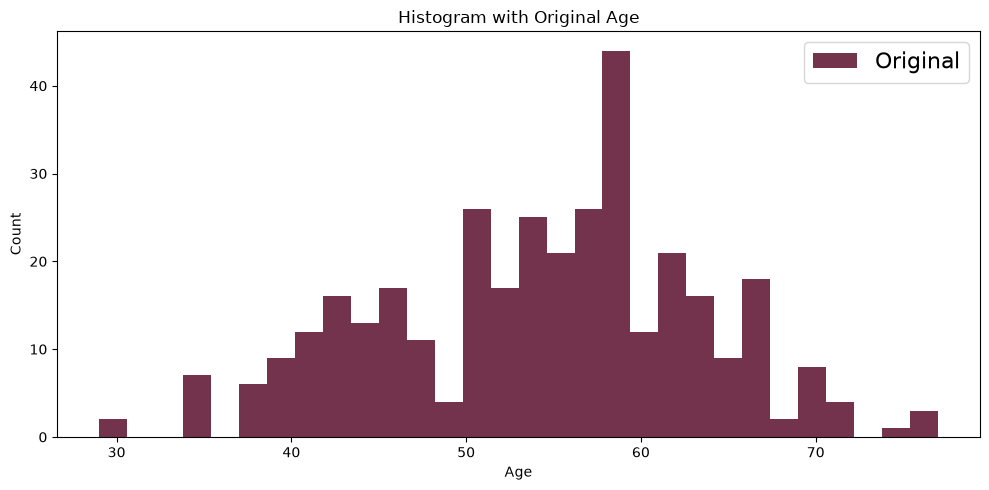

In [96]:
# =============================================================================
# 9. HISTOGRAM OF ORIGINAL (UNSCALED) TRAINING AGE
# =============================================================================

# dropna() excludes missing values from the visualization only
age = X_train_original["age"].dropna()

# Create a new figure; figsize values are in inches
plt.figure(figsize=(10, 5))

plt.hist(
    age, 
    color="#73334d",  # uses the publication palette for the histogram
    bins=30, # partitions the age range into 30 intervals
    # alpha=0.5, # makes bars 50% transparent
    label="Original" # supplies the text displayed by plt.legend()
)

# Add legend, title, and axis descriptions
plt.legend(prop={"size": 16})
plt.title("Histogram with Original Age")
plt.xlabel("Age")
plt.ylabel("Count")

# Prevent label clipping and render the figure
plt.tight_layout()
plt.show()

## 10. Min–Max Normalization of `age`

`MinMaxScaler` maps the training minimum to 0 and the training maximum to 1 using:

$$
x_{\mathrm{scaled}}=\frac{x-x_{\min,\mathrm{train}}}{x_{\max,\mathrm{train}}-x_{\min,\mathrm{train}}}
$$

The fitted scaler is then reused for the test set. 

Test values can lie outside [0, 1] if they exceed the training range. 

We use separate `X_train_normalized` and `X_test_normalized` copies so the next section can standardize the original ages independently.

For this demonstration, the code requires non-missing ages. If ages are missing, impute them using a training-fitted imputer first.

In [97]:
# =============================================================================
# 10. NORMALIZE AGE WITH MINMAXSCALER, FITTING ON TRAINING ONLY
# =============================================================================

# Create independent copies; do not overwrite X_train_original
X_train_normalized = X_train_imputed.copy()
X_test_normalized = X_test_imputed.copy()

# Scaling requires an appropriate numerical input
# Fail clearly if missing ages require prior imputation
if X_train_normalized["age"].isna().any() or X_test_normalized["age"].isna().any():
    raise ValueError("Missing age values: impute age using training data before scaling.")

# Initialize the scaler; default feature_range is (0, 1)
normalizer = MinMaxScaler()

# .to_numpy() extracts numerical values from the pandas Series
# .reshape(-1, 1) makes a 2D array: (observations, one feature)
# fit_transform() learns the TRAINING min/max and transforms training ages
# .ravel() converts the one-column output to a 1D array for assignment
X_train_normalized["age"] = normalizer.fit_transform(
    X_train_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_train_normalized["age"])

130    0.208333
245    0.645833
157    0.333333
16     0.458333
339    0.500000
         ...   
252    0.687500
100    0.500000
319    0.520833
66     0.625000
294    0.250000
Name: age, Length: 350, dtype: float64


In [98]:
# transform() uses the same training min/max; never fit on the test set
X_test_normalized["age"] = normalizer.transform(
    X_test_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_test_normalized["age"])

83     0.687500
25     0.666667
420    0.520833
177    0.416667
68     0.562500
         ...   
341    0.520833
380    0.541667
1      0.500000
142    0.583333
332    0.479167
Name: age, Length: 88, dtype: float64


In [99]:
# Display the training-derived scaling parameters and observed ranges
print("Training minimum age:\n", normalizer.data_min_[0])
print("\nTraining maximum age:\n", normalizer.data_max_[0])
print("\nNormalized training range:\n",
      (X_train_normalized["age"].min(), X_train_normalized["age"].max()))
print("\nNormalized testing range:\n",
      (X_test_normalized["age"].min(), X_test_normalized["age"].max()))

Training minimum age:
 29.0

Training maximum age:
 77.0

Normalized training range:
 (np.float64(0.0), np.float64(0.9999999999999999))

Normalized testing range:
 (np.float64(0.10416666666666663), np.float64(0.8749999999999999))


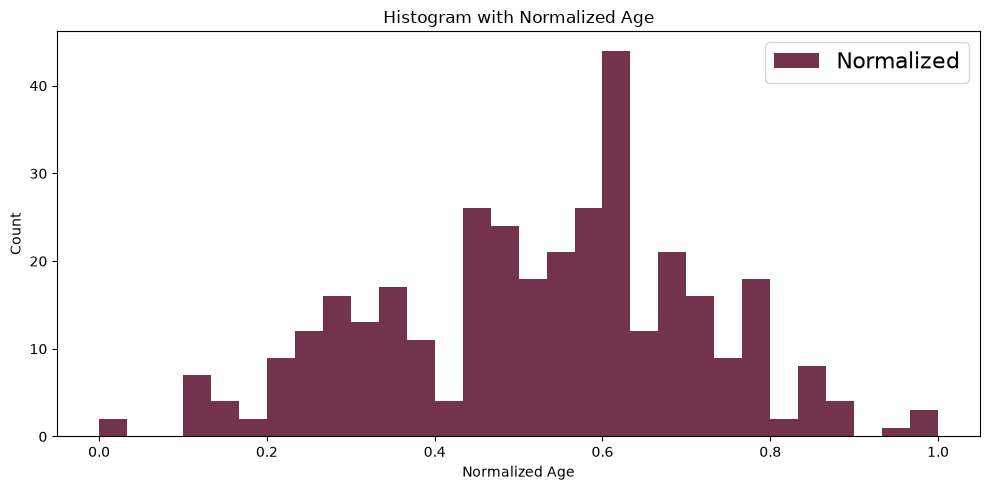

In [100]:
# Plot the normalized training ages (not the held-out test observations)
plt.figure(figsize=(10, 5))
plt.hist(
    X_train_normalized["age"], 
    bins=30, 
    color="#73334d", 
    # alpha=0.7, 
    label="Normalized"
)
plt.legend(prop={"size": 16})
plt.title("Histogram with Normalized Age")
plt.xlabel("Normalized Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 11. Z-Score Standardization of `age`

`StandardScaler` uses the training mean and standard deviation:

$$
z=\frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
$$

This gives training ages a mean near 0 and population standard deviation near 1 (scikit-learn uses `ddof=0`). 

**Standardization does not make a skewed variable normally distributed.** 

The test set is transformed using the same training-derived mean and standard deviation.

Crucially, we start again from the unscaled data, not from the min–max-normalized age column.

In [101]:
# =============================================================================
# 11. STANDARDIZE AGE WITH STANDARDSCALER, FITTING ON TRAINING ONLY
# =============================================================================

# Create fresh copies of the imputed, but NOT age-scaled, partitions
# This prevents accidentally standardizing already-normalized values
X_train_standardized = X_train_imputed.copy()
X_test_standardized = X_test_imputed.copy()

# Initialize StandardScaler; defaults center and scale the variable
standardizer = StandardScaler()

# fit_transform() learns mean and standard deviation from TRAINING age
# reshape(-1, 1) supplies the 2D shape scikit-learn expects
# ravel() returns a 1D array suitable for assigning to one column
X_train_standardized["age"] = standardizer.fit_transform(
    X_train_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_train_standardized["age"])

130   -1.681613
245    0.641232
157   -1.017943
16    -0.354273
339   -0.133050
         ...   
252    0.862455
100   -0.133050
319   -0.022438
66     0.530620
294   -1.460390
Name: age, Length: 350, dtype: float64


In [102]:
# Apply training-derived parameters to test age without refitting
X_test_standardized["age"] = standardizer.transform(
    X_test_imputed["age"].to_numpy().reshape(-1, 1)
).ravel()

print(X_test_standardized["age"])

83     0.862455
25     0.751843
420   -0.022438
177   -0.575497
68     0.198785
         ...   
341   -0.022438
380    0.088173
1     -0.133050
142    0.309397
332   -0.243662
Name: age, Length: 88, dtype: float64


In [104]:
# Inspect the learned parameters and the training result
print("Training mean age:\n", standardizer.mean_[0])
print("\nTraining population std. dev.:\n", standardizer.scale_[0])
print("\nStandardized training mean:\n", X_train_standardized["age"].mean())
print("\nStandardized training population std. dev.:\n",
      X_train_standardized["age"].std(ddof=0))

Training mean age:
 54.20285714285714

Training population std. dev.:
 9.040637958345503

Standardized training mean:
 2.0301221021717148e-16

Standardized training population std. dev.:
 1.0


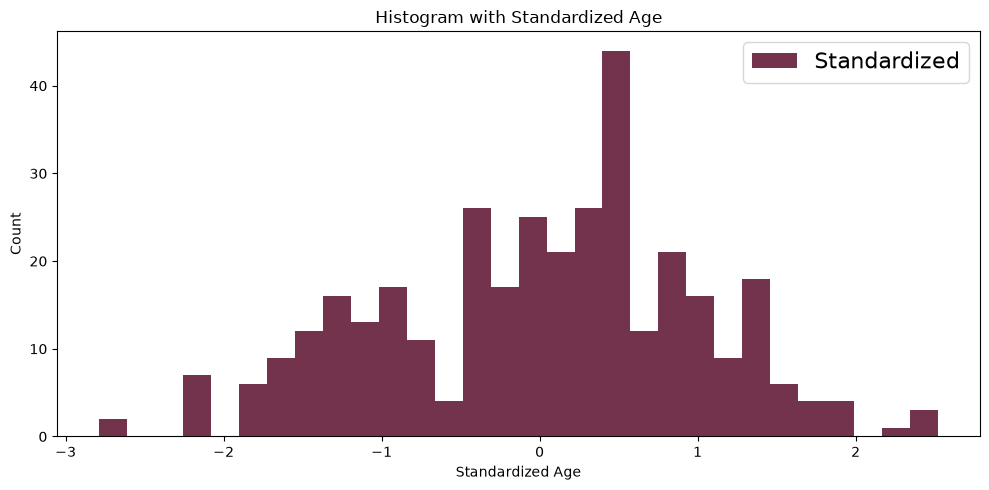

In [105]:
# Visualize the standardized training distribution
plt.figure(figsize=(10, 5))
plt.hist(
    X_train_standardized["age"], 
    bins=30, 
    color="#73334d", 
    # alpha=0.7, 
    label="Standardized"
)
plt.legend(prop={"size": 16})
plt.title("Histogram with Standardized Age")
plt.xlabel("Standardized Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [106]:
# Inspect the dimensions of the standardized training dataset
print(X_train_standardized.shape)

(350, 12)


## 12. Compare Results and Validate Assumptions

Compare the original, normalized, and standardized age columns to confirm that each transformation was applied to a separate copy. 

Check the expected training-set properties and revisit the distinction between `.shape` and `.count()`.

The histogram shapes remain similar because min–max normalization and z-score standardization are linear transformations of the same observations. Their **scales** change, not the ordering of values.

A complete modeling pipeline would also handle missingness in other predictors and, where appropriate, categorical encoding. 

Later exercises introduce fold-local preprocessing with `Pipeline` and `ColumnTransformer`.


In [107]:
# =============================================================================
# 12. VALIDATE PREPROCESSING RESULTS
# =============================================================================

# Summarize the same training age observations on three different scales
# ddof=0 matches the population standard deviation used by StandardScaler
summary = pd.DataFrame({
    "original": X_train_original["age"],
    "normalized": X_train_normalized["age"],
    "standardized": X_train_standardized["age"],
}).agg(["count", "mean", "std", "min", "max"])

print("Training age summary (pandas std uses ddof=1):")
print(summary)

Training age summary (pandas std uses ddof=1):
         original  normalized  standardized
count  350.000000  350.000000  3.500000e+02
mean    54.202857    0.525060  2.030122e-16
std      9.053581    0.188616  1.001432e+00
min     29.000000    0.000000 -2.787730e+00
max     77.000000    1.000000  2.521630e+00


In [108]:
# Verify that original ages were not overwritten by either scaler
assert X_train_original["age"].equals(X_train_imputed["age"])

# Verify that the fitted training scaler produces approximately zero mean
assert np.isclose(X_train_standardized["age"].mean(), 0.0, atol=1e-10)

# Check that normalized training ages are within the default [0, 1] range
assert X_train_normalized["age"].between(0, 1).all()

# Verify train and test partitions have the same predictor columns
assert X_train_original.columns.equals(X_test_original.columns)

print("\nValidation checks passed.")


Validation checks passed.


## 13. Quick Reference: pandas and scikit-learn Methods

| Expression | Meaning |
|---|---|
| `df.head()` | First five rows (default) |
| `df.info()` | Prints schema, non-null counts, dtypes, memory use |
| `df.shape` | `(rows, columns)`; **no parentheses** |
| `df['sex'].count()` | Number of non-missing entries |
| `df['sex'].value_counts()` | Counts per category |
| `df['sex'].value_counts(dropna=False)` | Category counts including missing values |
| `df['restecg'].mean()` | Mean of non-missing numeric values |
| `df['restecg'].fillna(value)` | Returns values with missing entries filled |
| `df.drop(columns=['oldpeak'])` | Drops a specified column |
| `df.dropna(axis='columns', how='all')` | Drops columns entirely composed of missing values |
| `df.drop_duplicates()` | Removes repeated rows |
| `df['age'].isna().any()` | Whether any ages are missing |
| `train_test_split(...)` | Separates training and test observations |
| `scaler.fit_transform(X_train)` | Learns training parameters and transforms training data |
| `scaler.transform(X_test)` | Applies already-learned parameters to test data |
| `.reshape(-1, 1)` | Reshapes a 1D array into a one-feature 2D array |
| `.ravel()` | Flattens the one-column output into a 1D array |

### Final checklist

- The CSV is read from the local project, without downloading substitutes.
- Cleaning and transformation decisions are explicit.
- Training and testing data remain separate.
- Imputation and scaling parameters are learned on training data only.
- Original, normalized, and standardized ages remain available for comparison.
- Histograms are descriptive and do not imply clinical conclusions.

**Suggested next step:** Explore feature types and missingness in the remaining predictors, then construct a scikit-learn preprocessing pipeline and baseline classifier.

### Model-Based Feature Selection: Training-Derived Decisions

The random forest ranks predictors using impurity-based importance. `SelectFromModel` retains predictors whose importance meets the chosen threshold. These scores are not causal effects and can be biased toward variables with more possible split points. Imputation is fitted on the training partition, and the same transformations and selection mask are applied to held-out observations. The intermediate imputation demonstration is retained to show why categorical `cp` and continuous `chol` require different treatment.

## 14. Random Forest: Model-Based Feature Selection

**Exercise.** Fit a random forest classifier with `n_jobs=-1`, `class_weight='balanced'`, and `max_depth=5`, then use `SelectFromModel` to retain features meeting the default importance threshold.

The existing notebook preserves the raw, imputed, normalized, and standardized partitions separately. 

This section uses **`X_train_imputed`** and **`X_test_imputed`** as the modeling inputs so that the earlier demonstrations remain unchanged. Random forests do not generally require standardization. The existing imputer was fitted on training data only.

**Assumptions:** The outcome `y_train` represents classification labels, and every predictor supplied to the random forest is numeric and has no missing values. The code checks these assumptions and raises an informative error rather than silently changing the exercise's preprocessing methodology. Feature selection is fitted using training observations only; the test set is transformed with the same selector. Because `random_state` was not specified in the instructional exercise, results may vary between runs.


In [ ]:
# =============================================================================
# DIAGNOSTIC: IDENTIFY REMAINING MISSING VALUES
# =============================================================================

# Count missing observations separately for each predictor
# 
# .isna():
#     Returns True for missing values and False otherwise
# 
# .sum():
#     Counts the True values within each column
# 
# .loc[lambda counts: counts > 0]:
#     Retains only columns containing at least one missing value

missing_train = (
    X_train_imputed.isna()
    .sum()
    .loc[lambda counts: counts > 0]
)

missing_test = (
    X_test_imputed.isna()
    .sum()
    .loc[lambda counts: counts > 0]
)

# Display the missing-value counts for both partitions
print("Missing values in training data:")
print(missing_train)

print("\nMissing values in testing data:")
print(missing_test)

In [ ]:
# =============================================================================
# 14.1. IMPUTE REMAINING MISSING VALUES FOR RANDOM FOREST FEATURE SELECTION
# =============================================================================

# Import SimpleImputer from scikit-learn
# SimpleImputer replaces missing observations using statistics calculated from the available values in a dataset
# 
# IMPORTANT:
# Fit each imputer exclusively on the training partition
# Apply the learned replacement values to the testing partition using transform() rather than fit_transform()
# This prevents information from the testing dataset from influencing preprocessing decisions (data leakage)

from sklearn.impute import SimpleImputer

In [ ]:
# Create independent copies of the training and test data

# =============================================================================

# STEP 1: CREATE INDEPENDENT COPIES OF THE IMPUTED DATASETS
# =============================================================================

# Preserve the existing training and testing datasets
# 
# .copy():
# Creates an independent pandas DataFrame so that subsequent modifications do not alter X_train_imputed or X_test_imputed
# 
# These datasets already contain the training-derived imputation previously applied to the 'restecg' predictor

X_train_rf = X_train_imputed.copy()
X_test_rf = X_test_imputed.copy()

In [ ]:
# Impute the categorical chest-pain predictor

# =============================================================================

# STEP 2: IMPUTE THE CATEGORICAL PREDICTOR 'cp'
# =============================================================================

# 'cp' represents chest pain type
# 
# Although its categories may be encoded using integers, those numbers represent categories rather than continuous numerical measurements
# 
# strategy="most_frequent":
# Replaces missing observations with the most frequently occurring category (mode) in the training partition
# 
# This preserves valid categorical values and avoids introducing potentially meaningless values through mean or median imputation

cp_imputer = SimpleImputer(strategy="most_frequent")


# Fit the imputer on training observations and replace missing values
# 
# Double brackets [['cp']]:
# Return a two-dimensional pandas DataFrame, as expected by scikit-learn's SimpleImputer
# 
# fit_transform():
# Learns the most frequent category from the training data and replaces missing values using that category
# 
# .ravel():
# Converts the resulting (n_samples, 1) NumPy array into a one-dimensional array suitable for assignment to a pandas column

X_train_rf["cp"] = cp_imputer.fit_transform(
    X_train_rf[["cp"]]
).ravel()


# Apply the same training-derived replacement category to testing data
# 
# transform():
# Reuses the category learned during training
# 
# Do not refit the imputer on X_test_rf

X_test_rf["cp"] = cp_imputer.transform(
    X_test_rf[["cp"]]
).ravel()

In [ ]:
# Impute the numerical cholesterol predictor

# =============================================================================

# STEP 3: IMPUTE THE CONTINUOUS PREDICTOR 'chol'
# =============================================================================

# 'chol' represents serum cholesterol
# 
# Unlike 'cp', cholesterol is a continuous numerical measurement
# 
# strategy="median":
# Replaces missing observations with the median cholesterol value calculated from the training partition
# 
# The median is less sensitive to extreme observations than the mean, making it a reasonable default for potentially skewed measurements

chol_imputer = SimpleImputer(strategy="median")

# Learn the training-set median and replace missing training values

X_train_rf["chol"] = chol_imputer.fit_transform(
    X_train_rf[["chol"]]
).ravel()

# Apply the same training-derived median to testing observations
# 
# This ensures consistent preprocessing across both partitions
# without using testing data to estimate replacement values

X_test_rf["chol"] = chol_imputer.transform(
    X_test_rf[["chol"]]
).ravel()

In [549]:
# Inspect the imputation statistics learned from training data

# =============================================================================

# STEP 4: INSPECT THE LEARNED IMPUTATION VALUES
# =============================================================================

# statistics_:
# A fitted SimpleImputer attribute containing the replacement statistic learned for each input column
# 
# [0]:
# Extracts the statistic for the first (and only) column supplied to each imputer

print("Training-derived replacement values:")

print(
    "Most frequent chest pain category (cp):",
    cp_imputer.statistics_[0]
)

print(
    "Median serum cholesterol (chol):",
    chol_imputer.statistics_[0]
)

Training-derived replacement values:
Most frequent chest pain category (cp): 0.0
Median serum cholesterol (chol): 240.0


In [ ]:
# =============================================================================
# STEP 5: VALIDATE THE IMPUTED DATASETS
# =============================================================================

# Count remaining missing values across all columns and observations
# 
# .isna():
# Identifies missing observations
# 
# .sum().sum():
# First counts missing observations within each column, then sums those counts across all columns

print("\nRemaining missing values in training (X_train_rf):")
print(X_train_rf.isna().sum().sum())

print("\nRemaining missing values in testing (X_test_rf):")
print(X_test_rf.isna().sum().sum())

# Confirm that neither partition contains missing values
# 
# These assertions raise AssertionError if any missing values remain

assert not X_train_rf.isna().any().any(), (
    "Training data still contain missing values."
)

assert not X_test_rf.isna().any().any(), (
    "Testing data still contain missing values."
)

In [ ]:
# =============================================================================
# 14.2. TRAIN A RANDOM FOREST FOR MODEL-BASED FEATURE SELECTION
# =============================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

# Initialize the random forest classifier
# 
# n_jobs=-1:
# Uses all available CPU cores for supported parallel operations
# 
# class_weight="balanced":
# Adjusts class weights inversely to their frequencies in the training data
# 
# max_depth=5:
# Limits the maximum depth of each decision tree to five, reducing model complexity

rf = RandomForestClassifier(
    n_jobs=-1,
    class_weight="balanced",
    max_depth=5,
    random_state=42,  # Reproduce tree sampling and feature-importance rankings
)

# Fit the random forest exclusively on training observations
# The model learns decision-tree structures and feature importance scores without accessing the testing target labels

rf.fit(X_train_rf, y_train)

print(
    "Random forest fitted on",
    X_train_rf.shape[0],
    "training rows."
)

### 14.3. Select Important Features and Transform Both Partitions

Because the random forest has already been fitted, `SelectFromModel(..., prefit=True)` can use its learned feature importances directly.

The selector's `get_support()` method returns a Boolean mask identifying the retained columns. Its `transform()` method produces a NumPy array containing those columns in their original order.

Apply the **same fitted selector** to the held-out test partition. Refitting feature selection on test data would compromise the evaluation.


In [ ]:
# =============================================================================
# 14.3. SELECT FEATURES AND APPLY THE TRAINING-DERIVED SELECTION MASK
# =============================================================================

# -------------------------------------------------------------------------

# Step 1: Initialize the model-based feature selector
# -------------------------------------------------------------------------

# SelectFromModel:
# Selects predictors based on feature importance scores learned by an estimator, such as a random forest
# 
# rf:
# The previously fitted RandomForestClassifier
# 
# prefit=True:
# Indicates that the estimator has already been fitted
# 
# Consequently, SelectFromModel reuses the feature importance scores stored in rf.feature_importances_ 
# Instead of fitting the random forest again
# 
# threshold:
# When unspecified, SelectFromModel uses the mean feature importance as the threshold for this random forest
# 
# IMPORTANT:
# The random forest was fitted exclusively on training data
# Therefore, the feature-selection decisions are derived from training observations rather than testing observations

feature_selector = SelectFromModel(rf, prefit=True)

In [ ]:
# Apply the selected feature mask to both partitions

# -------------------------------------------------------------------------

# Step 2: Apply the learned feature-selection mask
# -------------------------------------------------------------------------

# .to_numpy():
# Converts a pandas DataFrame into a NumPy array
# 
# This removes pandas column-name metadata while preserving the underlying values and their column order
# 
# Why convert to NumPy?
# With prefit=True, SelectFromModel may not retain the original feature names, even when its estimator was trained on a DataFrame
# 
# Passing NumPy arrays avoids feature-name consistency warnings
# 
# IMPORTANT:
# The training and testing DataFrames must have identical predictor columns in the same order
# 
# transform():
# Applies the feature-selection mask learned from the fitted random forest
# 
# The output is a two-dimensional NumPy array containing only the selected predictors
# 
# No additional fitting occurs during these transformations

X_train_transformed = feature_selector.transform(
    X_train_rf.to_numpy()
)

X_test_transformed = feature_selector.transform(
    X_test_rf.to_numpy()
)

In [ ]:
# Retrieve the Boolean feature-selection mask

# -------------------------------------------------------------------------

# Step 3: Retrieve the feature-selection mask
# -------------------------------------------------------------------------

# get_support():
# Returns a one-dimensional Boolean NumPy array
# 
# Each element corresponds to one original predictor:
# 
# True  -> Predictor was selected
# False -> Predictor was excluded
# 
# Example:
# [False, True, False, True, ...]
# 
# The mask follows the original column order

features_bool = feature_selector.get_support()

In [ ]:
# Recover the selected predictor names

# -------------------------------------------------------------------------

# Step 4: Recover the selected predictor names
# -------------------------------------------------------------------------

# X_train_rf.columns:
# A pandas Index containing the original predictor names
# 
# Boolean indexing:
# Retains only the column names corresponding to True values in the feature-selection mask
# 
# The resulting pandas Index preserves the original feature order

selected_features = X_train_rf.columns[features_bool]

In [ ]:
# Display the selected predictors and output dimensions

# -------------------------------------------------------------------------

# Step 5: Display the selected features and transformed dimensions
# -------------------------------------------------------------------------

print(f"\nSelected features:\n {selected_features}")

print("\nOriginal training shape:\n", X_train_rf.shape)

print("\nSelected training shape:\n", X_train_transformed.shape)

print("\nSelected test shape:\n", X_test_transformed.shape)

In [442]:
# Confirm both transformed datasets have the same selected columns
assert X_train_transformed.shape[1] == X_test_transformed.shape[1]
assert X_train_transformed.shape[1] == len(selected_features)

### 14.4. Visualize Random Forest Feature Importance

`rf.feature_importances_` contains impurity-based importance scores for **all** original predictors. Indexing it with `features_bool` selects the scores corresponding to `selected_features`. Importance measures contributions to impurity reduction in this model, **not** causal effects. Correlated or high-cardinality predictors can make these scores misleading.

In [ ]:
# =============================================================================
# 14.4. VISUALIZE IMPORTANCE SCORES FOR SELECTED FEATURES
# =============================================================================

# Use the same Boolean mask for names and scores so they stay aligned
feature_importance = pd.DataFrame({
    "feature": selected_features,
    "importance": rf.feature_importances_[features_bool],
})

# A horizontal bar chart makes feature labels easier to read
plt.figure(figsize=(10, 6))
plt.barh(feature_importance["feature"], feature_importance["importance"])
plt.title("Random Forest Importance of Selected Features")
plt.xlabel("Impurity-based feature importance")
plt.ylabel("Selected feature")
plt.tight_layout()
plt.show()

## 15. Support Vector Classification (SVC): Required Imports

**Exercise.** 

Import `train_test_split` from `sklearn.model_selection` and `SVC` from `sklearn.svm`. `train_test_split` partitions predictors and outcomes; `SVC` implements a support vector classifier. 

The split function was already imported in Section 0, but this cell repeats the two required imports together to match the exercise. 

Re-importing the same function does not split the data again.

Unlike random forests, SVC is generally sensitive to feature scales. When fitting an SVC in a later exercise, standardize the **appropriate numerical features** using training-derived parameters, ideally inside a scikit-learn `Pipeline`. 

**No SVC model is fitted in this exercise.**


In [218]:
# =============================================================================
# 15. IMPORT TRAIN/TEST SPLITTING AND SUPPORT VECTOR CLASSIFICATION
# =============================================================================

# train_test_split(X, y, ...) divides aligned features and labels into separate training and testing partitions
# It was used earlier in Section 7
from sklearn.model_selection import train_test_split

# SVC is scikit-learn's Support Vector Classifier
# A future exercise may initialize SVC(...) and call .fit(X_train, y_train) after suitable scaling
from sklearn.svm import SVC


## 16. Split the Heart Disease Data for SVC (80:20)

**Exercise requirement.** 

Use `train_test_split(heart_disease_X, heart_disease_y, test_size=0.2, random_state=42)` to allocate approximately 80% of observations to training and 20% to testing. 

The `random_state` argument fixes the random partition for reproducibility; this exercise does **not** request stratification.

The notebook already calls its feature matrix `X` and target vector `y` (Section 7). 

We assign the exercise-specific names as **aliases**, not copies or newly processed datasets, to preserve the expected DataCamp variable names. 

The split in this section intentionally **reassigns** `X_train`, `X_test`, `y_train`, and `y_test`, as required by the exercise. 

Earlier snapshot variables such as `X_train_original` and `X_train_imputed` are not modified. 

Because Section 7 may have used stratification, this new split need not match the earlier one.

> **Data-leakage reminder:** Split before fitting imputers or scalers. The split alone does not impute missing values or scale features. `SVC` needs numeric, finite features; if the original feature matrix contains missing or nonnumeric values, the following model-fitting exercise may raise an error. Such a limitation is reported rather than silently changing the requested exercise.

This section starts a **separate SVC exercise** with a newly generated train-test split. Subsequent SVC and logistic-regression examples use these new partitions; their results should not be interpreted as evaluations on the earlier random-forest split.

In [446]:
# Review the inputs before creating the next train-test split
# Check the dimensions of the feature matrix (X) and target vector (y)
print("X:", X.shape)  # returns (number of observations, number of features)
print("y:", y.shape)  # returns (number of observations,)

X: (438, 12)
y: (438,)


In [447]:
# Verify that the target variable is a pandas Series
print(type(y))

# Check the number of missing target values
print(y.isna().sum())

<class 'pandas.Series'>
0


In [449]:
# Count missing values before fitting the SVC
missing_counts = X.isna().sum()

# Display only features with at least one missing observation
print(missing_counts[missing_counts > 0])

cp         49
chol       49
restecg    44
dtype: int64


In [ ]:
# =============================================================================
# 16. SPLIT HEART-DISEASE FEATURES AND LABELS (80% / 20%)
# =============================================================================

# Reuse the notebook's existing predictors (X) and target labels (y)
# These aliases reference the original objects without modifying their contents
# Fit new imputers on the new training split to avoid carrying over statistics from an earlier split
heart_disease_X = X
heart_disease_y = y

# Import the required scikit-learn functions and classes
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC

# Split predictors and labels into training (80%) and testing (20%) sets
# random_state=42 ensures reproducibility
# Preserve DataCamp's unstratified split rather than using stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    heart_disease_X,
    heart_disease_y,
    test_size=0.20,
    random_state=42,
)

# Inspect the dimensions of the resulting partitions
print("Training feature shape:\n", X_train.shape)
print("\nTesting feature shape:\n", X_test.shape)
print("\nTraining labels shape:\n", y_train.shape)
print("\nTesting labels shape:\n", y_test.shape)

## 17. Fit a Linear Support Vector Classifier and Predict

**Exercise requirement.** Initialize `svc_model = SVC(kernel='linear')`, fit it with `svc_model.fit(X_train, y_train)`, and generate held-out predictions with `y_pred = svc_model.predict(X_test)`.

- `SVC` implements support vector classification. With `kernel='linear'`, its separating decision boundary is a hyperplane in the original predictor space. `C` retains its default value of 1.0, controlling the penalty for margin violations.
- `.fit(X_train, y_train)` learns the classifier using **training labels only**. `.predict(X_test)` applies that fitted classifier to test features and returns a one-dimensional NumPy array of predicted class labels, aligned row-by-row with `X_test` and `y_test`.
- Printing `y_pred` displays predicted labels; it **does not** evaluate their accuracy. The test labels remain available for a later evaluation exercise.

> **Important practical limitation:** This exercise deliberately uses the DataCamp statements without introducing extra preprocessing. Linear SVC generally benefits from standardization; any imputer or scaler should be fitted on training data only and reused for test data. The current raw features may include missing or nonnumeric values, which can prevent fitting. The code below checks for these conditions and raises a clear error rather than silently modifying the dataset or inventing an unrequested preprocessing workflow. Earlier Section 8 demonstrates training-only imputation, and Section 11 demonstrates training-only standardization.

In [ ]:
# =============================================================================
# 17. IMPUTE MISSING VALUES BEFORE FITTING A LINEAR SVC
# =============================================================================

# Verify that all predictors are numeric before applying the SVC
# Numeric encoding is required even when a feature represents categories
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train.dtypes):
    raise TypeError(
        "SVC training features contain nonnumeric columns. "
        "Encode these predictors using training-fitted preprocessing."
    )

# Create independent copies to preserve the original training and test sets
X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()

In [ ]:
# Create independent training and test copies

# Identify categorical and numerical features requiring imputation
# cp and restecg are categorical variables represented by numeric codes
categorical_columns = ["cp", "restecg"]

# chol is a continuous numerical variable
numerical_columns = ["chol"]

# Initialize imputers with appropriate replacement strategies
categorical_imputer = SimpleImputer(
    strategy="most_frequent" # replaces missing categories with their training-set mode
)

numerical_imputer = SimpleImputer(
    strategy="median" # replaces missing numerical values with their training-set median
)

In [ ]:
# Impute categorical predictors from training observations

# Fit the categorical imputer on training data and replace missing values
X_train_imputed[categorical_columns] = categorical_imputer.fit_transform(
    X_train[categorical_columns]
)

# Apply the same training-derived replacement categories to the test data
# transform() prevents test-set information from influencing imputation
X_test_imputed[categorical_columns] = categorical_imputer.transform(
    X_test[categorical_columns]
)

In [ ]:
# Impute numerical predictors from training observations

# Fit the numerical imputer using the training-set cholesterol distribution
X_train_imputed[numerical_columns] = numerical_imputer.fit_transform(
    X_train[numerical_columns]
)

# Apply the training-derived cholesterol median to the test set
X_test_imputed[numerical_columns] = numerical_imputer.transform(
    X_test[numerical_columns]
)

In [451]:
# Display the replacement values learned from training data

# Display the replacement values learned exclusively from training data
print("\nTraining-derived categorical replacement values:")
print(dict(zip(categorical_columns, categorical_imputer.statistics_)))

print("\nTraining-derived numerical replacement values:")
print(dict(zip(numerical_columns, numerical_imputer.statistics_)))


Training-derived categorical replacement values:
{'cp': np.float64(0.0), 'restecg': np.float64(1.0)}

Training-derived numerical replacement values:
{'chol': np.float64(243.0)}


In [452]:
# Count remaining missing values in each feature after imputation
train_missing = X_train_imputed.isna().sum()
test_missing = X_test_imputed.isna().sum()

# Retain only features containing at least one missing value
train_missing = train_missing[train_missing > 0]
test_missing = test_missing[test_missing > 0]

# Display remaining missing values or confirm successful imputation
print("\nRemaining missing values in training:")
print(train_missing if not train_missing.empty else "None")

print("\nRemaining missing values in testing:")
print(test_missing if not test_missing.empty else "None")

# Stop execution if either partition still contains missing values
if not train_missing.empty or not test_missing.empty:
    raise ValueError(
        "Missing values remain after imputation. "
        "Inspect the affected features before fitting the SVC."
    )


Remaining missing values in training:
None

Remaining missing values in testing:
None


In [ ]:
# =============================================================================
# 17. FIT A LINEAR SVC AND PREDICT TEST LABELS
# =============================================================================

# Initialize a support vector classifier with a linear kernel
# Other parameters, including regularization C=1.0, retain their defaults
svc_model = SVC(kernel="linear")

# Fit the classifier using only the imputed training predictors and labels
# Test observations and labels are excluded from model fitting
svc_model.fit(X_train_imputed, y_train)

# Predict class labels for the imputed test observations
# predict() returns a 1D NumPy array aligned with the test-set rows
svc_y_pred = svc_model.predict(X_test_imputed)

# Display the predicted class labels
print("\nPredicted test labels:")
print(svc_y_pred)

### Evaluation and Experiment Tracking: Separate Estimators, Separate Questions

The linear SVC, logistic regression, and random-forest feature selector teach different operations. Their fitted objects and predictions should remain distinguishable. A held-out test accuracy evaluates one trained estimator; cross-validation fits **new estimators within each fold** and evaluates on fold-specific validation data. MLflow records model parameters and metadata; logging coefficients does not retrain the model.

When comparing the SVC and logistic-regression results, remember that the estimators use different preprocessing: the SVC receives imputed predictors, while logistic regression uses scaled predictors. The comparison therefore concerns the **complete modeling procedures**, not only the algorithms in isolation.

## 18. Track Logistic Regression Coefficients with MLflow

**Exercise:** Select the MLflow experiment `Logistic Regression Heart Disease Prediction`, start a run, log every learned coefficient (`coef_0`, `coef_1`, …) and the intercept as parameters, and print the run ID.

> **Prerequisite and naming conflict:** The exercise assumes `model` is an already-fitted **logistic regression** estimator. In this notebook, however, Section 14A assigned `model = SelectFromModel(rf, prefit=True)`. That object does **not** have logistic-regression `coef_` or `intercept_` attributes. No logistic regression training exercise is available in the provided post-revision conversation. Accordingly, this cell checks that the correct fitted estimator is present and stops with an informative error if it is not. **It does not overwrite or silently train `model`.** Before running, assign a fitted logistic-regression estimator to `model` in a separately authorized workflow.

`mlflow.set_experiment()` selects or creates an experiment; `mlflow.start_run()` is a context manager that closes the run automatically. `enumerate(model.coef_[0])` yields zero-based indices and coefficient values. The intercept and coefficients are **learned parameters**, not hyperparameters; the exercise nevertheless requests `mlflow.log_param()`. 

MLflow must be installed and configured in the active environment. No tracking run is started during notebook construction.

In [ ]:
# =============================================================================
# 18. FIT A LOGISTIC REGRESSION MODEL AND PREDICT TEST LABELS
# =============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Initialize a standard scaler to normalize feature scales
scaler = StandardScaler()

# Fit the scaler on training data and standardize the training predictors
# Apply the same training-derived scaling parameters to the test predictors
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Initialize a logistic regression classifier
logistic_model = LogisticRegression(
    max_iter=1000, # allows additional iterations if needed for convergence
    random_state=42 # ensures reproducibility where applicable
)

# Fit the classifier using only the training predictors and labels
logistic_model.fit(X_train_scaled, y_train)

# Predict class labels for the test observations
logistic_y_pred = logistic_model.predict(X_test_scaled)

# Display the predicted class labels
print("\nPredicted test labels:")
print(logistic_y_pred)

# Calculate the model's classification accuracy on the test set
accuracy = logistic_model.score(X_test_scaled, y_test)

print(f"\nTest accuracy: {accuracy:.2%}")

In [ ]:
import copy

# Inspect the fitted estimator type before logging its coefficients
print(type(logistic_model))

# Create an independent copy of the fitted logistic regression model
tracked_logistic_model = copy.deepcopy(logistic_model)

# Inspect the fitted estimator type before logging its coefficients
print(type(tracked_logistic_model))

In [457]:
# Import MLflow and verify that the package is available
import mlflow

# Display the installed MLflow version
print("MLflow version:", mlflow.__version__)

MLflow version: 3.17.2


In [ ]:
# =============================================================================
# 18. LOG FITTED LOGISTIC-REGRESSION COEFFICIENTS WITH MLFLOW
# =============================================================================

# MLflow tracks related model experiments, their runs, and logged values
# This import requires the optional `mlflow` package in the active kernel
from sklearn.linear_model import LogisticRegression
from sklearn.utils.validation import check_is_fitted

# Keep the experiment-tracking classifier separate from the feature selector
# The fitted estimator was copied from logistic_model in the preceding section
if not isinstance(tracked_logistic_model, LogisticRegression):
    raise TypeError(
        "Experiment tracking requires a fitted LogisticRegression estimator."
    )

# A LogisticRegression instance may exist but still be unfitted
# This check raises NotFittedError if learned attributes are unavailable
check_is_fitted(tracked_logistic_model)

# Reuse an existing experiment with this name or create it if absent
mlflow.set_experiment("Logistic Regression Heart Disease Prediction")

# The `with` context starts one run and closes it on exit (even on error)
with mlflow.start_run():
    # coef_ has one row in binary classification; [0] selects that row
    # enumerate supplies (index, coefficient) pairs for unique log keys
    for idx, coef in enumerate(tracked_logistic_model.coef_[0]):
        # Cast NumPy scalars to native Python floats for compatibility
        mlflow.log_param(f"coef_{idx}", float(coef))

    # The binary logistic regression intercept is a length-one array
    mlflow.log_param("intercept", float(tracked_logistic_model.intercept_[0]))

    # Read the identifier while the run is active and display it
    run_id = mlflow.active_run().info.run_id
    print("MLflow run ID:", run_id)

## 19. Inspect the First Shuffled K-Fold Split

**Exercise:** Initialize `KFold`, use `next(kfold.split(heart_disease_df_X))` to retrieve the **first** pair of training and testing *row indices*, and print their lengths. The original exercise does not specify `n_splits` or `random_state`; the documented illustration below uses five folds and seed 42. These values are **assumptions**, not confirmed DataCamp requirements.

With five folds, roughly four-fifths of the rows are training indices and one-fifth validation indices. `shuffle=True` randomizes fold assignment reproducibly with `random_state=42`; `.split()` yields indices rather than actual DataFrames. For a pandas DataFrame, `.iloc[train_data_split]` would retrieve the rows by integer position. The exercise's `heart_disease_df_X` name is introduced as an alias for the already-defined `heart_disease_X`; no data are changed. In R, similar positional selection uses `data[indices, , drop=FALSE]`, remembering that R indices are one-based while NumPy indices are zero-based.

In [ ]:
# =============================================================================
# 19. FIRST SHUFFLED KFOLD TRAIN / VALIDATION INDEX SPLIT
# =============================================================================

from sklearn.model_selection import KFold

# Match the exercise's variable name without copying or changing features
heart_disease_df_X = heart_disease_X

# Five folds and seed 42 are illustrative assumptions
kfold = KFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42 # randomizes membership before assigning fold boundaries
)

# .split() returns an iterator of (train_indices, validation_indices)
# next() extracts its first pair; these arrays contain ROW POSITIONS
train_data_split, test_data_split = next(
    kfold.split(heart_disease_df_X)
)

# len(DataFrame) counts observations; len(index_array) counts selected rows
print("Number of training datapoints in heart_disease_df_X:\n", len(heart_disease_df_X))
print("\nNumber of training datapoints in split:\n", len(train_data_split))
print("\nNumber of testing datapoints in split:\n", len(test_data_split))

### Confusion-Matrix Input Provenance

The standalone exercise expects `actuals` and `predictions`, but their original course-provided arrays are unavailable. To demonstrate the **same confusion-matrix operation** without inventing historical observations, the revised cell derives both arrays from the notebook's existing held-out logistic-regression evaluation. These are real predictions from the supplied dataset, not the unavailable standalone exercise's original values.

## 20. Confusion Matrix for Actual and Predicted Diagnoses

**Exercise:** Import `confusion_matrix` and compare `actuals` (true diagnoses) with `predictions` (predicted diagnoses). The original exercise supplies those two arrays externally, but they are **not defined** in the uploaded notebook or the provided conversation. The code therefore checks for them rather than substituting unrelated predictions. Supply the exercise's arrays before executing.

For binary labels ordered as `[0, 1]`, rows represent actual classes and columns represent predicted classes: 

`[[TN, FP], [FN, TP]]`

This interpretation depends on the label encoding; confirm whether 1 represents disease. False negatives correspond to positive cases missed by the classifier. The matrix counts observations; it is not itself a cross-validation score.

In [ ]:
# =============================================================================
# 20. CONFUSION MATRIX OF PROVIDED DIAGNOSES
# =============================================================================
from sklearn.metrics import confusion_matrix

# This standalone exercise originally expected externally supplied arrays
# The source values are not available in the accompanying CSV
# To preserve the operation without inventing historical labels, use a clearly
# labeled illustration with the already fitted logistic model's test predictions
# Both arrays are drawn from the same held-out test partition
actuals = y_test.to_numpy()
predictions = logistic_y_pred

# Argument order matters: true labels FIRST, predicted labels SECOND
# Each matrix entry counts observations with the corresponding label pair
cm = confusion_matrix(actuals, predictions)
print(cm)

In [ ]:
# Compare the standalone example with predictions from the fitted classifier
from sklearn.metrics import classification_report, confusion_matrix

# Evaluate predictions against the actual test labels
print(classification_report(y_test, logistic_y_pred))

In [ ]:
# Display the confusion matrix
print("\nConfusion matrix:")
print(confusion_matrix(y_test, logistic_y_pred))

### *EXPLORE FURTHER*
**Compare the two classifiers already trained**

Accuracy summarizes overall correctness, while balanced accuracy gives equal weight to each class's recall. Comparing the existing linear SVC and logistic regression on the **same held-out test labels** provides a small, realistic model-evaluation table. Both models were fitted earlier; this extension does not retrain them, tune hyperparameters, or select a winner based on the test set. The table is descriptive, not a substitute for cross-validation.

In [ ]:
# =============================================================================
# 20.1. COMPARE EXISTING CLASSIFIERS ON THE SAME TEST SET
# =============================================================================

from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Reuse predictions already generated by the SVC and logistic regression cells
# Each prediction array must correspond to the same y_test observations
model_predictions = {
    "Linear SVC": svc_y_pred,
    "Logistic regression": logistic_y_pred,
}

# Collect two familiar classification metrics for each existing model
# Balanced accuracy averages recall across the observed target classes
model_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
    }
    for name, predictions in model_predictions.items()
])

# Display scores as proportions between 0 and 1, rounded for readability
print("Held-out test performance (descriptive comparison):")
print(model_comparison.round(3).to_string(index=False))

## 21. Five-Fold Balanced Accuracy Evaluation and Confusion Matrix

**Exercise sequence:** Define `kf = KFold(n_splits=5)` (without shuffling), evaluate a logistic-regression estimator using `cross_val_score(..., scoring='balanced_accuracy', cv=kf)`, print fold scores, call `model.predict(heart_disease_df_X)`, and compute `confusion_matrix(heart_disease_df_y, y_pred)`.

**Metric correction:** The user explicitly confirmed `scoring='balanced_accuracy'`, **not** `'accuracy'`. Balanced accuracy averages per-class recall (for binary classification, sensitivity and specificity). It can be more informative when diagnoses are imbalanced.

**Prerequisites:** The exercise says `model` is a fitted logistic regression; the notebook's Section 14A currently uses `model` for `SelectFromModel`. This section checks the estimator type and fitted state, rather than changing earlier cells. `heart_disease_df_X` and `heart_disease_df_y` are aliases of the existing feature matrix and target. They may contain missing values or nonnumeric predictors; if so, model fitting will require a separately specified, leakage-safe preprocessing workflow. No missing steps are invented.

**Evaluation distinction:** `cross_val_score()` clones and fits a fresh estimator on each training fold; it does not reuse the fitted coefficients. In contrast, `model.predict(heart_disease_df_X)` uses the **existing fitted model** on all supplied rows, so its confusion matrix is **not necessarily out-of-fold** and may be optimistic if the model was trained on those rows. `KFold(shuffle=False)` does not preserve class proportions; for imbalanced diagnoses, stratification is often preferable, but the code retains DataCamp's requested method. Any learned preprocessing should be fitted separately within each training fold to prevent leakage.

**Evaluation boundary:** This cross-validation demonstration uses the complete cleaned feature dataset, including observations previously used in a held-out test partition. The fold scores illustrate cross-validation; they are **not** an independent validation of the earlier held-out test result. Each fold fits its own preprocessing through the pipeline.

In [ ]:
# =============================================================================
# 21. LOGISTIC REGRESSION: STRATIFIED CROSS-VALIDATION
# =============================================================================

import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [ ]:
# Reuse the cleaned predictors and identify preprocessing groups

# Reuse the original predictors and target labels
# Missing values will be handled independently within each training fold
heart_disease_df_X = heart_disease_X
heart_disease_df_y = heart_disease_y

# Identify categorical and numerical predictors
categorical_columns = ["cp", "restecg"]
numerical_columns = [
    col for col in heart_disease_df_X.columns
    if col not in categorical_columns
]

In [ ]:
# Define separate categorical and numerical preprocessing pipelines

# Define preprocessing for categorical predictors
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Define preprocessing for numerical predictors
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine preprocessing strategies
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_columns),
    ("numerical", numerical_transformer, numerical_columns)
])

In [ ]:
# Combine preprocessing with logistic regression

# Create a pipeline combining preprocessing and logistic regression
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

In [ ]:
# Configure stratified cross-validation

# Configure stratified 5-fold cross-validation
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True, # randomizes fold assignment while preserving class proportions
    random_state=42
)

In [472]:
# Evaluate balanced accuracy across validation folds

# Evaluate balanced accuracy across the five validation folds
# Each fold independently fits preprocessing and logistic regression
scores = cross_val_score(
    model_pipeline,
    heart_disease_df_X,
    heart_disease_df_y,
    scoring="balanced_accuracy",
    cv=kf
)

# Display the balanced accuracy obtained in each fold
print("Balanced accuracy by fold:")
print(scores)

# Summarize average performance and variability
print(f"\nMean balanced accuracy: {scores.mean():.2%}")
print(f"Standard deviation: {scores.std():.2%}")

Balanced accuracy by fold:
[0.81987578 0.88819876 0.8742236  0.84278897 0.7966596 ]

Mean balanced accuracy: 84.43%
Standard deviation: 3.37%


In [ ]:
# Predict test labels using the same scaling applied during training
logistic_y_pred = logistic_model.predict(X_test_scaled)

# Calculate the confusion matrix using previously unseen test observations
cm = confusion_matrix(y_test, logistic_y_pred, labels=[0, 1])

# Display the confusion matrix
print(cm)

## 22. Unit Testing Binary Model Inference with `unittest`

**Exercise sequence:** Import `unittest` and NumPy; create `TestModelInference(unittest.TestCase)`; implement `setUp()` to store the provided trained `model` and `X_test`; define `test_prediction_output_values(self)`; generate `y_pred = self.model.predict(self.X_test)`; use `np.unique(y_pred)` and `self.assertIn(value, [0, 1])` to verify that every distinct prediction is a permitted binary class label.

- **Test discovery:** `unittest` recognizes methods whose names start with `test_`. The `setUp()` hook runs **before each** test method, preparing its resources. `self` refers to the current test instance. Despite the exercise's phrase “class attribute,” `self.X_test` and `self.model` are **instance attributes**, not attributes on the class itself.
- **Inference vs. evaluation:** `.predict(X_test)` generates predicted class labels; it does not refit the model. `np.unique()` extracts the distinct labels, and `assertIn()` fails if a value is outside `[0, 1]`. This is a **contract/inference test**, not an accuracy or fairness test. An all-zero prediction vector passes, as does an empty prediction vector because the loop has no values to check.
- **Prerequisites:** DataCamp provides a **trained binary classifier** named `model` and a compatible feature matrix named `X_test`. Earlier notebook sections reuse `model` for a feature selector (`SelectFromModel`) and `X_test` for different workflows. Ensure the intended fitted classifier and corresponding test features are in scope before running; this new section does not silently replace them.
- **Running tests in a notebook:** Defining a `TestCase` class alone does **not** execute the test. In a Jupyter environment, a runner such as `unittest.TextTestRunner().run(unittest.defaultTestLoader.loadTestsFromTestCase(TestModelInference))` can run it when the prerequisites are available. The runner is described here, not invoked automatically, so the exercise's requested code remains unchanged.

**R comparison:** Python's `unittest` provides assertions and test discovery analogous in purpose to the R package `testthat` (for example, `expect_true()` and `expect_true(all(predictions %in% c(0, 1)))`).

In [ ]:
# =============================================================================
# 22. TEST THAT MODEL INFERENCE PRODUCES BINARY LABELS
# =============================================================================

# unittest is part of the Python standard library
# TestCase supplies setUp() lifecycle behavior and assertion methods such as assertIn()
import unittest

# NumPy's unique() returns the sorted, distinct values in an array
import numpy as np


class TestModelInference(unittest.TestCase):
    """Test the class-label contract of a previously trained classifier.

    The exercise uses the fitted logistic classifier and its scaled ``X_test``
    feature matrix to be available in the notebook's namespace.

    Attributes
    ----------
    model : sklearn-compatible fitted classifier
        Estimator used to predict binary labels; provided externally.
    X_test : pandas.DataFrame or numpy.ndarray
        Test observations whose columns and preprocessing must match
        the estimator's training-time input schema.

    Notes
    -----
    ``unittest.TestCase`` discovers methods named ``test_*``. These
    checks validate the allowed output labels, not predictive quality.
    """

    def setUp(self):
        """Make the existing classifier and test features available to tests.

        This lifecycle hook executes before **each** test method. The
        assignments create instance attributes, not class attributes,
        and do not train, copy, or mutate the supplied estimator or data.

        Returns
        -------
        None
            Initializes ``self.model`` and ``self.X_test``.
        """
        # `logistic_model` is the fitted binary classifier
        # Use the same scaling applied during logistic-regression training
        self.model = logistic_model

        # Store a reference to the supplied test feature matrix
        # `self` refers to the particular TestModelInference instance
        self.X_test = X_test_scaled

    def test_prediction_output_values(self):
        """Assert that each distinct predicted class belongs to {0, 1}.

        Returns
        -------
        None
            Successful assertions do not return a result.

        Raises
        ------
        AssertionError
            If any distinct predicted label is neither 0 nor 1.

        Notes
        -----
        This test allows predictions containing just one class and
        does not verify accuracy or nonempty output.
        """
        # Display the test name so the execution is easy to follow
        print("Running test_prediction_output_values test case")

        # predict() uses the already fitted estimator to return one predicted class label per input observation (no refitting)
        y_pred = self.model.predict(self.X_test)

        # Checking only unique labels avoids redundant assertions when many patients receive the same predicted label
        unique_values = np.unique(y_pred)

        # assertIn(member, collection) fails with AssertionError when an unexpected label such as 2 or -1 is encountered
        for value in unique_values:
            self.assertIn(value, [0, 1])

### Optional Infrastructure Boundary

The inference test below uses the already fitted logistic classifier and its **scaled** test features. Feast is a separate feature-store exercise: the supplied heart-disease CSV lacks the `patient_id`, `timestamp`, and `created` fields needed for the specified `FileSource`. Defining a schema is instructional, but registering a feature view requires the Feast package, a configured repository, and a compatible source. The notebook does not invent patient IDs or timestamps.

## 23. Define a Feast Patient Entity and Feature Schema

**Exercise:** Create an `Entity` called `patient` with join key `patient_id`, then define four `Field` objects: `cp` (`Float32`), `thalach` (`Int32`), `ca` (`Int32`), and `thal` (`Int32`). These are **Feast schema types**, not necessarily the same objects as NumPy or pandas dtypes. The exercise states that `Field` is imported for you; the standalone notebook cell explicitly imports the necessary Feast objects for clarity.

- **Entity:** Identifies the real-world subject (a patient) and the key used to join records. The source data must actually contain a compatible `patient_id` column.
- **Field:** Declares a feature name and its expected storage type. `cp` and `thal` can represent categorical codes despite their numerical storage types. Their statistical interpretation is separate from the Feast schema.
- **Schema vs. values:** Creating these Python objects defines metadata only; it does not create the underlying data, a `FeatureView`, or a deployed feature store.

**Prerequisites:** The third-party `feast` package and its supported dependencies must be installed in the active environment. The user-supplied exercise explicitly requires `Float32` for `cp`; that choice is preserved rather than silently replaced by an integer or categorical type.

In [ ]:
# =============================================================================
# 23. DEFINE A PATIENT ENTITY AND FOUR FEAST FEATURE FIELDS
# =============================================================================

# Feast stores feature metadata using Entity and Field objects
# The types below come from feast.types, not NumPy's dtype namespace
from feast import Entity, Field
from feast.types import Float32, Int32

# Entity identifies the real-world object represented by each record
# join_keys is a list because some entity schemas may use multiple keys
# this exercise uses the single source-data column "patient_id"
patient = Entity(name="patient", join_keys=["patient_id"])

# Field(name=..., dtype=...) declares a feature's schema, not its values
# `cp` represents chest pain type; preserve DataCamp's Float32 choice
cp = Field(name="cp", dtype=Float32)

# `thalach` represents maximum heart rate achieved, stored as Int32
thalach = Field(name="thalach", dtype=Int32)

# `ca` represents the number of major vessels, stored as Int32
ca = Field(name="ca", dtype=Int32)

# `thal` represents a thalassemia-related diagnostic category 
# Integer storage does not imply that its category codes are continuous numbers
thal = Field(name="thal", dtype=Int32)

## 24. Save Parquet Data, Define a Feast `FileSource` and `FeatureView`, and Register the Schema

**Exercise sequence:** Save `heart_disease_df` to `heart_disease.parquet`; create `FileSource(path="heart_disease.parquet", event_timestamp_column="timestamp", created_timestamp_column="created")`; define `heart_disease_fv = FeatureView(name="heart_disease", entities=[patient], schema=[cp, thalach, ca, thal], source=data_source)`; initialize `store = FeatureStore(repo_path=".")`; and call `store.apply([patient, heart_disease_fv])`.

**How the objects relate:** `patient` defines the entity key; the four `Field` objects describe feature names and types; `FileSource` points to the file and names the timestamp columns; `FeatureView` groups these components; `FeatureStore` connects to a configured Feast repository; and `apply()` registers the entity and feature view. Registration is **not** the same as loading data into an online store or performing historical feature retrieval.

**Important prerequisites and limitations (not silently repaired):**

1. `heart_disease_df` must already exist and include `patient_id`, `cp`, `thalach`, `ca`, `thal`, `timestamp`, and `created` with compatible data types. The earlier notebook's original CSV is not documented as containing the required patient ID and timestamps; this exercise **does not invent or add** those columns. The timestamps should be appropriate datetime values. `timestamp` denotes the event time used in point-in-time retrieval, while `created` can help distinguish versions of records.
2. Saving Parquet with pandas requires an installed engine such as `pyarrow`. The relative filename is resolved from the **current working directory**, not necessarily the notebook file's folder.
3. `FeatureStore(repo_path=".")` expects a valid Feast repository configuration, typically `feature_store.yaml`, at that location. The earlier notebook does not establish this configuration. Depending on the installed Feast version, the API may also have additional validation or configuration requirements. These examples preserve DataCamp's requested signatures rather than asserting that they work without those prerequisites.
4. Defining a `FeatureView` does not prove point-in-time correctness by itself. Historical retrieval must use suitable event timestamps and properly prepared source data; features computed using future observations can still cause leakage.
5. The source data may include additional columns, but only the four declared fields are included in this `FeatureView` schema. A schema declaration does not automatically fix missing, misnamed, or incompatible columns.

**R comparison:** `DataFrame.to_parquet()` serves a similar role to `arrow::write_parquet()` in R. Feast's Python-specific repository definitions are not directly interchangeable with an R data frame schema.

In [ ]:
# =============================================================================
# 24. CONFIGURE AND REGISTER A FILE-BACKED FEAST FEATURE VIEW
# =============================================================================

# Check the prerequisites for registering a Feast feature view
# The input DataFrame must contain the following columns:
# patient_id
# cp, thalach, ca, and thal
# timestamp and created with datetime-compatible values

# A Parquet engine and a configured Feast repository are also required
from feast import FileSource, FeatureView, FeatureStore

# The provided CSV does not contain patient_id, timestamp, or created
# A real Feast registration requires a source with those fields and a repository
# Do not invent patient identifiers or event times from the CSV
required_feast_columns = {"patient_id", "timestamp", "created", "cp", "thalach", "ca", "thal"}
missing_feast_columns = sorted(required_feast_columns - set(heart_disease_df.columns))
if missing_feast_columns:
    print("Feast registration example requires additional source columns:", missing_feast_columns)
    print("The schema definition above remains a valid instructional exercise")
else:
    # Write only when the supplied source has the required event-time schema
    heart_disease_df.to_parquet("heart_disease.parquet")

# Point Feast to the file written above
if not missing_feast_columns:
    data_source = FileSource(
    path="heart_disease.parquet",
    # These are column NAMES: both columns must exist in the source file
    event_timestamp_column="timestamp", # identifies when each observation was valid
    created_timestamp_column="created", # identifies when a version of that observation was recorded
    )
    
    # Group the four previously defined Field objects into a FeatureView
    # entities=[patient] associates values with the patient_id join key
    # schema declares the four available features and their expected types
    # source tells Feast where their underlying values are stored
    heart_disease_fv = FeatureView(
    name="heart_disease",
    entities=[patient],
    schema=[cp, thalach, ca, thal],
    source=data_source,
    )
    
    # Initialize the feature store from the Feast repository in the current working directory
    # A suitable feature_store.yaml must already exist
    store = FeatureStore(repo_path=".")
    
    # Register the entity and FeatureView definitions in Feast's registry
    # apply() does not automatically materialize feature values online
    store.apply([patient, heart_disease_fv])

## 25. Monitor January and February Prediction Distributions

**Exercise.** Production prediction logs are supplied as pandas DataFrames `logs_january` and `logs_february`. Each has a `target` column containing **predicted class labels** (not necessarily verified patient outcomes). Compare the monthly class counts using two Matplotlib bar charts.

- `Series.value_counts()` counts each observed label; `Series.plot(kind="bar", ax=...)` draws the counts on a selected subplot. `plt.subplots(1, 2, figsize=(15, 6))` creates a figure and a two-element array of axes.
- `plt.tight_layout()` reduces overlap, and `plt.show()` displays the figure.
- **Interpretation:** A change in predicted-label frequencies is a monitoring signal, not proof of a change in model accuracy or the cause of drift. Monthly sample sizes can differ. The instructional exercise compares **counts**; proportions and consistent class ordering are possible improvements, but are not substituted here.

**Prerequisites:** `logs_january`, `logs_february`, and their `target` columns must already exist. The notebook does not generate or fabricate Elastic Beanstalk logs.

### Reproducible Monitoring Demonstration — Illustrative Inputs

The original monitoring exercises use monthly logs and outcome labels supplied separately by the course. Those historical observations are **not** contained in `heart_disease_df_1.csv`. The next cell constructs **synthetic, reproducible teaching samples**, not real January/February production logs. This preserves the plotting, KS-test, and feedback-loop exercises while making them runnable without claiming that fabricated data were observed in production.

The KS test is most appropriate for continuous measurements; the demonstration uses continuous scores rather than binary labels for the KS comparisons. The prediction-frequency plots separately use binary predicted classes. The balanced-accuracy comparison uses a stated illustrative January baseline of 90%, not a measured January result. A detected drift or decline warrants investigation, not automatic retraining.

In [ ]:
# =============================================================================
# 25.1. PREPARE REPRODUCIBLE ILLUSTRATIVE MONITORING INPUTS
# =============================================================================

# This exercise uses explicitly synthetic data because historical monthly
# monitoring records are not supplied with the heart-disease CSV
# The fixed random seed makes this illustration reproducible
import numpy as np
import pandas as pd

monitor_rng = np.random.default_rng(42)
monitor_n = 200

# Simulate continuous feature measurements for distribution-shift tests
# The February mean is deliberately shifted for teaching purposes
january_data = monitor_rng.normal(loc=0.0, scale=1.0, size=monitor_n)
february_data = monitor_rng.normal(loc=0.55, scale=1.0, size=monitor_n)
jan_data_samples = january_data.copy()
feb_data_samples = february_data.copy()

# Create two prediction-log tables with the target column expected below
# The proportions are illustrative, not actual model outputs
logs_january = pd.DataFrame({"target": monitor_rng.binomial(1, 0.48, monitor_n)})
logs_february = pd.DataFrame({"target": monitor_rng.binomial(1, 0.62, monitor_n)})

# Generate synthetic binary outcomes and imperfect predictions for February
# This does not estimate real deployed model performance
true_labels_feb = monitor_rng.binomial(1, 0.5, monitor_n)
predicted_labels_feb = true_labels_feb.copy()
flip_indices = monitor_rng.choice(monitor_n, size=40, replace=False)
predicted_labels_feb[flip_indices] = 1 - predicted_labels_feb[flip_indices]

print("Illustrative monthly monitoring inputs prepared (synthetic data)")


In [ ]:
# =============================================================================
# 25. COMPARE PREDICTED CLASS FREQUENCIES BY MONTH
# =============================================================================

# pyplot supplies figures, axes, layout adjustment, and rendering
# The DataCamp environment imports plt; importing explicitly here makes this notebook cell's dependency clear when run in VS Code
import matplotlib.pyplot as plt

# One row and two columns give a separate Axes for each month
# figsize is expressed in inches (width, height)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Select the prediction-label Series and count occurrences of each label
# By default, value_counts() sorts by frequency, so bar order can differ between months
logs_january['target'].value_counts().plot(
    kind='bar', # requests vertical bars
    ax=ax[0] # chooses the subplot
)

ax[0].set_title('Distribution of Predicted Classes - January')
ax[0].set_xlabel('Class')
ax[0].set_ylabel('Frequency')

# Repeat the identical procedure for February to support comparison
logs_february['target'].value_counts().plot(kind='bar', ax=ax[1])

ax[1].set_title('Distribution of Predicted Classes - February')
ax[1].set_xlabel('Class')
ax[1].set_ylabel('Frequency')

# Prevent labels from overlapping; then display the complete figure
plt.tight_layout()
plt.show()

## 26. Detect Distributional Change with the Two-Sample KS Test

**Exercise.** Compare the supplied `january_data` and `february_data` with `scipy.stats.ks_2samp()`. The function returns a statistic and a p-value; Python can unpack these as `test_statistic, p_value`.

**Null hypothesis:** The two independent samples are drawn from the same distribution. The KS statistic is the largest absolute gap between their empirical cumulative distribution functions (ECDFs). The exercise uses the decision rule `p_value < 0.05` to print `"Data drift detected."`; otherwise it prints `"No data drift detected."`.

**Statistical cautions:** Failure to reject the null is not proof of identical distributions. The classical KS p-value is best calibrated for independent observations from continuous distributions; binary predicted labels have ties, so a proportion-based test may be more appropriate for that specific use case. Statistical significance does not measure practical importance or prove degraded predictive performance.

**Prerequisites:** The exercise provides `january_data` and `february_data`; they are not generated by this notebook. They should represent comparable, one-dimensional samples of the same monitored quantity.

In [ ]:
# =============================================================================
# 26. KOLMOGOROV-SMIRNOV TEST FOR MONTHLY DATA DRIFT
# =============================================================================

# Import the two-sample KS test from SciPy's statistics module
from scipy.stats import ks_2samp

# Compare the two supplied sample distributions
# The returned object can be unpacked into (1) the maximum ECDF difference and (2) the p-value
# This is a distributional test, not a measure of classification accuracy
test_statistic, p_value = ks_2samp(january_data, february_data)

# DataCamp's 5% significance threshold: 
# reject the equal-distribution null hypothesis when the p-value is strictly less than 0.05
if p_value < 0.05:
    print("Data drift detected.")
else:
    print("No data drift detected.")

## 27. Feedback Loops — Monitor Balanced Accuracy and Drift

**Exercise sequence.** A deployed binary heart-disease classifier is monitored over time. January's **balanced accuracy** is provided as `90.0` percent. February's `true_labels_feb` and `predicted_labels_feb` allow direct performance measurement using `balanced_accuracy_score`; `jan_data_samples` and `feb_data_samples` are separately supplied for the two-sample KS drift test.

- **Balanced accuracy** is the average of class-wise recall; for two classes, it is `(sensitivity + specificity) / 2`. Scikit-learn returns a proportion, so multiplying by `100` makes February comparable to January's 90.0% baseline.
- The inline conditional expression `'Yes' if condition else 'No'` displays whether February's measured balanced accuracy is lower. A decrease alone does not establish statistical significance or an automatic need to retrain.
- `ks_2samp` returns a KS statistic and p-value; `significant_drift = p_value < 0.05` records DataCamp's binary alert rule. The two signals answer different questions: **predictive performance** versus **distributional change**.
- A feedback loop can include collecting outcomes, measuring performance, monitoring shifts, investigating causes, and deciding whether to retrain or adjust. Drift does not by itself prove that retraining will help. In medical classification, sensitivity, specificity, validation quality, and clinical consequences also matter.

**Prerequisites:** All four sample/label variables are provided by the instructional exercise and are **not** available automatically from the notebook's earlier heart-disease DataFrame. The labels must correspond to the same February observations. The KS samples should be comparable and suitable for the test.

In [ ]:
# =============================================================================
# 27. FEEDBACK-LOOP PERFORMANCE AND DRIFT MONITORING
# =============================================================================

# balanced_accuracy_score averages recall over the classes, mitigating misleading results from class imbalance
# ks_2samp compares distributions
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import ks_2samp

# January's 90.0 is a supplied baseline expressed as a PERCENTAGE
balanced_accuracy_jan = 90.0

# Actual February labels are the first argument
# Model predictions are second
# Multiply the returned fraction by 100 to match January's units
balanced_accuracy_feb = balanced_accuracy_score(
    true_labels_feb,
    predicted_labels_feb,
) * 100

# :.2f prints two digits after the decimal point
# The conditional expression chooses 'Yes' only when February's score is strictly lower
print(f"Model Balanced Accuracy In February: {balanced_accuracy_feb:.2f}%")
print(
    f"Is there a decline in accuracy? "
    f"{'Yes' if balanced_accuracy_feb < balanced_accuracy_jan else 'No'}"
)

# Compare the separately supplied January/February monitoring samples
# The KS statistic measures the maximum difference between ECDFs
ks_statistic, p_value = ks_2samp(jan_data_samples, feb_data_samples)

# Store the 5% significance decision as a Boolean (True or False)
significant_drift = p_value < 0.05

# :.4f displays four decimal places
# Small p-values may round to 0.0000, which does NOT mean that their exact numerical value is zero
print(f"Kolmogorov-Smirnov Statistic: {ks_statistic:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Is there significant data drift? {'Yes' if significant_drift else 'No'}")

### 27A. Knowledge Check: Should the Model Enter a Retraining Feedback Loop?

**Question:** Based on the model's accuracy and the data-drift evaluation, should the system consider retraining or adjustments?

**Answer choices from the instructional exercise:**

1. Yes, but only due to data drift.
2. Yes, but only due to the accuracy drop.
3. Yes, both the accuracy drop and data drift indicate the model needs retraining.
4. No, the model seems to be performing well and there's no significant data drift.

**How to decide:** Inspect the outputs from Section 27. If February's balanced accuracy falls below 90% **and** the KS p-value is below 0.05, **option 3** matches the exercise's decision rule. If only one signal is present, choose option 1 or 2. If neither is present, choose option 4.

**Important limitation:** The monitoring inputs are synthetic, so these results illustrate the decision process rather than real-world model degradation. Even when both signals are present, retraining should be investigated and validated—not triggered unconditionally.
